# DBMS Fundamentals: Distributed Databases, Data Warehousing and Database Security

> **Who is this for?** A beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and the
> earlier notebooks of this module, or a BS/MS student revising the "advanced topics" chapters of a DBMS course
> (the last third of most syllabi) for an exam or a system-design interview.
>
> **What you will learn**
> - **Distributed databases**: homogeneous vs heterogeneous systems, fragmentation (horizontal, vertical, mixed) with
>   reconstruction checks, replication (synchronous, asynchronous, quorums), distributed query processing with the
>   **semi-join**, **two-phase commit** (including a coordinator crash), three-phase commit, Paxos/Raft,
>   the **CAP theorem** and **PACELC** stated precisely, BASE vs ACID, sharding and **consistent hashing**.
> - **Data warehousing**: OLTP vs OLAP, warehouse architecture, **star / snowflake / galaxy schemas** built in SQLite,
>   **slowly changing dimensions** (types 1 and 2), the **OLAP operations** (roll-up, drill-down, slice, dice, pivot),
>   ROLAP/MOLAP/HOLAP and data marts.
> - **Data mining**: the KDD process and where each step lives in this repo.
> - **Big-data stores**: HDFS, HBase, Hive and the modern **lakehouse** (Parquet + Delta Lake / Iceberg).
> - **Database security**: authentication vs authorization, GRANT/REVOKE and RBAC, **SQL injection** (attacked and fixed),
>   encryption, auditing, the **statistical-database inference problem**, and GDPR-style data minimisation.
>
> **Prerequisites**: SQL basics ([`../01_sql/01_sql_fundamentals.ipynb`](../01_sql/01_sql_fundamentals.ipynb)) and the relational model ([`03_relational_model_and_relational_algebra.ipynb`](./03_relational_model_and_relational_algebra.ipynb)),
> transactions and ACID ([`05_transactions_and_concurrency_control.ipynb`](./05_transactions_and_concurrency_control.ipynb)), normalisation ([`04_functional_dependencies_and_normalization.ipynb`](./04_functional_dependencies_and_normalization.ipynb)), indexing ([`07_indexing_b_trees_and_hashing.ipynb`](./07_indexing_b_trees_and_hashing.ipynb)). Light pandas
> ([`../../02_Data_Analysis/03_pandas.ipynb`](../../02_Data_Analysis/03_pandas.ipynb)).
>
> **Time needed**: about 3–4 hours (the notebook itself runs in well under a minute).
>
> **Runs on**: CPU, no API key, no server, no network. Every "distributed" system here is **simulated** in plain Python,
> and every database is SQLite in memory.
>
> **Optional track**: this notebook is part of the **university-level fundamentals track**; it is recommended for BS/MS AI
> students and for interview preparation, but the rest of the repo does not depend on it.

### How this notebook relates to the rest of `13_Databases`

| Already in the repo | What it covers | What this notebook adds |
|---|---|---|
| [`../02_nosql/01_nosql_databases.ipynb`](../02_nosql/01_nosql_databases.ipynb) | MongoDB, Redis, Cassandra APIs, a first look at CAP | The **theory**: CAP's exact statement, PACELC, quorums, consistent hashing, 2PC |
| [`../../22_ML_System_Design/04_nosql_and_data_stores.ipynb`](../../22_ML_System_Design/04_nosql_and_data_stores.ipynb) | Choosing a store for an ML system; lake / warehouse / lakehouse; medallion layers | Dimensional modelling, SCDs, OLAP operations, how table formats achieve ACID |
| [`../06_data_engineering/01_data_engineering.ipynb`](../06_data_engineering/01_data_engineering.ipynb) | ETL vs ELT, Spark, Kafka, dbt, Delta Lake, Airflow | The warehouse **design** that those pipelines load into |
| [`../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb`](../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb) | Parameterized queries in an ML pipeline | SQL injection explained as a **security** topic, plus GRANT/REVOKE, auditing and inference attacks |

### Contents
1. [Setup](#1-setup)
2. [Distributed databases: what and why](#2-distributed-databases-what-and-why)
3. [Fragmentation](#3-fragmentation)
4. [Replication](#4-replication)
5. [Distributed query processing and the semi-join](#5-distributed-query-processing-and-the-semi-join)
6. [Distributed commit: 2PC and 3PC](#6-distributed-commit-2pc-and-3pc)
7. [Consensus, CAP, PACELC, BASE](#7-consensus-cap-pacelc-base)
8. [Sharding and consistent hashing](#8-sharding-and-consistent-hashing)
9. [Data warehousing: OLTP vs OLAP and architecture](#9-data-warehousing-oltp-vs-olap-and-architecture)
10. [Dimensional modelling: star, snowflake, galaxy](#10-dimensional-modelling-star-snowflake-galaxy)
11. [Slowly changing dimensions](#11-slowly-changing-dimensions)
12. [OLAP operations](#12-olap-operations)
13. [ROLAP, MOLAP, HOLAP and data marts](#13-rolap-molap-holap-and-data-marts)
14. [Data mining and the KDD process](#14-data-mining-and-the-kdd-process)
15. [Big-data stores: HDFS, HBase, Hive, lakehouse](#15-big-data-stores-hdfs-hbase-hive-lakehouse)
16. [Database security](#16-database-security)
17. [How this connects to modern AI](#17-how-this-connects-to-modern-ai)
18. [Recap, practice problems, further reading](#18-recap)

## Explained simply

When a company gets big, one computer can no longer hold all its data or answer all its users, so the data is spread
over many computers that must still behave like **one** database: that is a **distributed database**. Keeping several copies
of the data is great for safety (if one machine breaks, another has the data), but keeping the copies in agreement is hard:
either you wait for every copy before saying "done" (correct but slow), or you don't wait (fast, but someone may briefly see
old data). A **data warehouse** is a separate store that keeps years of history, arranged for big questions like
"sales per month per city", while the everyday database is busy taking orders. **Database security** decides who may see and
change which data, and stops tricks such as typing pieces of SQL into a login box.

**Everyday examples**
- A WhatsApp message shows as delivered on your phone a moment before it appears on your friend's laptop: that delay is
  **replication lag**.
- A library with branches in three cities keeps each city's books locally (**fragmentation**) but shares one catalogue;
  a school keeps a daily attendance register (the busy everyday database) and a separate archive of report cards for
  long-term analysis (the **warehouse**).
- A bank gives the cashier a key to the cash drawer but not to the vault: that is **GRANT / REVOKE** in real life.

**A tiny example.** A shop has tills in Lahore, Karachi and Islamabad. Today they sold 5, 3 and 2 pens. Head office asks
"how many pens in the whole country?": 5 + 3 + 2 = 10. Adding the city totals into one country total is a **roll-up**.
Now suppose Karachi's internet is down. Head office can either **wait** until Karachi is back (always correct, but no answer
yet) or **answer 7 now** (always answers, but may be out of date). That forced choice is the **CAP theorem**.

| In one line | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Distributed database | one database spread over many computers that act as one | banks, WhatsApp, Google, the vector databases behind AI search |
| Data warehouse | a history store built for asking big questions | sales dashboards, the data used to train ML models |
| SQL injection | tricking a database by typing code into an input box | hacked login forms; "prompt injection" is the same trick on LLM apps |

---
## 1. Setup

> **In plain English:** load the tools; nothing to understand yet.

Only the standard library, numpy, pandas, matplotlib and networkx are needed. Everything random is seeded, so you get
the same numbers as the text every time you run the notebook.

In [1]:
import bisect                       # binary search on the consistent-hashing ring
import hashlib                      # stable hash functions (md5 for the ring, pbkdf2 for passwords)
import hmac                         # keyed hashing for pseudonymisation and constant-time comparison
import itertools                    # combinations for the quorum check
import json                         # the mini lakehouse transaction log
import os                           # file sizes in the lakehouse demo
import shutil                       # clean up the temporary folder at the end
import sqlite3                      # the relational database used throughout
import tempfile                     # a throw-away folder for files
import time                         # simple timings
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

SEED = 42
rng = np.random.default_rng(SEED)   # numpy random generator (seeded)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
TMP = tempfile.mkdtemp(prefix="dbms09_")   # every file we write goes here and is deleted at the end
print("SQLite version:", sqlite3.sqlite_version, "| pandas", pd.__version__, "| networkx", nx.__version__)

SQLite version: 3.45.1 | pandas 2.3.3 | networkx 3.7


---
## 2. Distributed databases: what and why

> **In plain English:** many computers in different places, working together so that users see one database.

**Analogy.** A national bank cannot keep every account in one building: customers in Lahore, Karachi and Islamabad want
fast service, and a fire in one building must not stop the bank. So each city keeps the accounts it uses most, some data
is copied to several cities, and a set of rules makes the whole thing *look like one bank* to a customer.

**Definition (Özsu & Valduriez).** A **distributed database (DDB)** is a collection of multiple, logically interrelated
databases distributed over a computer network. A **distributed DBMS (DDBMS)** is the software that manages the DDB and makes
the distribution **transparent** to users.

```
            user / application  (sees ONE logical database)
                        │
              ┌─────────┴─────────┐   global schema, global query optimiser,
              │      DDBMS        │   distributed transaction manager
              └───┬─────┬─────┬───┘
         network  │     │     │
            ┌─────┴┐ ┌──┴───┐ ┌┴─────┐
            │Site 1│ │Site 2│ │Site 3│   each site: local DBMS + local data
            │Lahore│ │Karach│ │Islamb│
            └──────┘ └──────┘ └──────┘
```

**Kinds of transparency** a DDBMS tries to provide:

| Transparency | The user does not need to know... |
|---|---|
| **Location** | at which site a table (or fragment) is stored |
| **Fragmentation** | that a table is split into pieces |
| **Replication** | that copies exist and which copy is used |
| **Network / naming** | network details; every object has a unique global name |
| **Transaction (concurrency + failure)** | that a transaction touches several sites; it is still atomic |

### Homogeneous vs heterogeneous

| | **Homogeneous DDBMS** | **Heterogeneous DDBMS** (multidatabase / federated) |
|---|---|---|
| Local DBMS software | the same at every site (e.g. all PostgreSQL) | different (e.g. Oracle + MongoDB + a CSV-based legacy system) |
| Schema | usually one global schema designed top-down | local schemas exist first; a global (federated) schema is mapped on top, bottom-up |
| Site autonomy | low: sites cooperate fully | high: each site keeps control of its own data |
| Example | a sharded PostgreSQL cluster (Citus), CockroachDB, Google Spanner | Trino/Presto federating PostgreSQL + Hive + MySQL, Oracle Database Gateways |
| Hard part | partitioning and replication | schema mapping, type conversion, different transaction models |

**Advantages** of distribution: data locality (lower latency), reliability/availability (no single point of failure), scale-out,
organisational autonomy. **Costs**: harder query optimisation (network cost), distributed transactions and concurrency
control, partial failures, harder administration and security.

> 🎓 **Exam tip.** "Distributed database" ≠ "parallel database". A **parallel DBMS** runs on tightly coupled processors
> (often in one data centre, shared-nothing or shared-disk) mainly for *speed*; a **distributed DBMS** runs on loosely
> coupled, possibly geographically separated sites, mainly for *locality, autonomy and availability*. Many modern systems are both.

---
## 3. Fragmentation

> **In plain English:** cut a big table into pieces (by rows, by columns, or both) and keep each piece where it is used most, without losing anything.

**Fragmentation** splits a relation $R$ into smaller relations (**fragments**) that can be stored at different sites.
There are three kinds:

| Kind | How a fragment is defined | How to rebuild $R$ | Example |
|---|---|---|---|
| **Horizontal** | a **selection** $R_i = \sigma_{p_i}(R)$ (a subset of *rows*) | **union** $R = R_1 \cup R_2 \cup \dots$ | employees of each city stored in that city |
| **Vertical** | a **projection** $R_i = \pi_{K, A_i}(R)$ (a subset of *columns*, always including the key $K$) | **natural join** on $K$: $R = R_1 \bowtie R_2 \bowtie \dots$ | salary columns stored only at the payroll site |
| **Mixed / hybrid** | a selection of a projection (or vice versa) | joins and unions in the right order | payroll columns, then split by city |

A fragmentation is **correct** only if it satisfies three rules:
1. **Completeness**: every row (horizontal) or every attribute (vertical) of $R$ appears in at least one fragment.
2. **Reconstruction**: $R$ can be rebuilt exactly from the fragments with relational operators (union / join).
3. **Disjointness**: a row is in at most one horizontal fragment; for vertical fragments, the *non-key* attributes do not overlap
   (the key must be repeated, otherwise rows cannot be joined back together).

A worked example by hand, horizontal fragmentation of a tiny table by `city`:

```
EMPLOYEE                          EMP_LHR = σ city='Lahore'   EMP_KHI = σ city='Karachi'
emp_id name   city                emp_id name  city            emp_id name  city
1      Ali    Lahore      ──►     1      Ali   Lahore          2      Sara  Karachi
2      Sara   Karachi             3      Omar  Lahore
3      Omar   Lahore                                   EMP_LHR ∪ EMP_KHI = EMPLOYEE  ✔
```

Below we write a small checker that tests all three rules on pandas DataFrames.

In [2]:
# A small EMPLOYEE relation (12 rows) that we will fragment in several ways
employees = pd.DataFrame({
    "emp_id": range(1, 13),
    "name":   ["Ali", "Sara", "Omar", "Ayesha", "Bilal", "Hina", "Usman", "Zara", "Hamza", "Fatima", "Imran", "Nadia"],
    "dept":   ["Sales", "IT", "IT", "HR", "Sales", "IT", "HR", "Sales", "IT", "HR", "Sales", "IT"],
    "city":   ["Lahore", "Karachi", "Lahore", "Islamabad", "Karachi", "Lahore",
               "Islamabad", "Lahore", "Karachi", "Lahore", "Islamabad", "Karachi"],
    "salary": [90, 120, 110, 85, 95, 130, 80, 92, 125, 88, 99, 118],   # thousands per month
    "phone":  [f"03{i:02d}-555{i:04d}" for i in range(1, 13)],
})
KEY = "emp_id"


def same_relation(a: pd.DataFrame, b: pd.DataFrame) -> bool:
    """True if a and b contain exactly the same rows and columns (order ignored), like relations (sets)."""
    if set(a.columns) != set(b.columns):
        return False
    cols = sorted(a.columns)
    a2 = a[cols].sort_values(KEY).reset_index(drop=True)
    b2 = b[cols].sort_values(KEY).reset_index(drop=True)
    return a2.equals(b2)


def check_horizontal(original, fragments):
    """Check completeness, disjointness and reconstruction (by UNION) of horizontal fragments."""
    ids = [set(f[KEY]) for f in fragments]                         # which rows each fragment holds
    complete = set().union(*ids) == set(original[KEY])           # every row is somewhere
    disjoint = sum(len(s) for s in ids) == len(set().union(*ids))  # no row in two fragments
    rebuilt = pd.concat(fragments).drop_duplicates()              # UNION (set semantics)
    return {"complete": complete, "disjoint": disjoint, "reconstructs": same_relation(original, rebuilt)}


def check_vertical(original, fragments):
    """Check completeness, disjointness (of non-key attributes) and reconstruction (by JOIN on the key)."""
    attrs = [set(f.columns) - {KEY} for f in fragments]
    has_key = all(KEY in f.columns for f in fragments)            # the key must be in every fragment
    complete = set().union(*attrs) | {KEY} == set(original.columns)
    disjoint = sum(len(a) for a in attrs) == len(set().union(*attrs))
    rebuilt = None
    if has_key:
        rebuilt = fragments[0]
        for f in fragments[1:]:
            rebuilt = rebuilt.merge(f, on=KEY)                    # natural join on the key
    ok = has_key and same_relation(original, rebuilt)
    return {"key_in_every_fragment": has_key, "complete": complete, "disjoint": disjoint, "reconstructs": ok}


# 1) HORIZONTAL: one fragment per city (selection predicates city = c)
h_frags = [employees[employees.city == c] for c in ["Lahore", "Karachi", "Islamabad"]]
print("Horizontal by city      :", check_horizontal(employees, h_frags))

# 2) VERTICAL: public HR data vs. private payroll data (key repeated in both)
v_frags = [employees[["emp_id", "name", "dept", "city"]], employees[["emp_id", "salary", "phone"]]]
print("Vertical HR | payroll   :", check_vertical(employees, v_frags))

# 3) MIXED: first vertical (HR part / payroll part), then the HR part horizontally by city
hr_part, payroll = v_frags
mixed = {c: hr_part[hr_part.city == c] for c in ["Lahore", "Karachi", "Islamabad"]}
rebuilt_mixed = pd.concat(mixed.values()).merge(payroll, on=KEY)   # UNION the city pieces, then JOIN payroll
print("Mixed reconstructs      :", same_relation(employees, rebuilt_mixed))

# Two WRONG fragmentations, to see the checker catch them
bad_h = [employees[employees.city == "Lahore"], employees[employees.city == "Karachi"]]            # forgot Islamabad
bad_v = [employees[["emp_id", "name", "dept", "city"]], employees[["salary", "phone"]]]            # key not repeated
print("Forgot a city           :", check_horizontal(employees, bad_h))
print("Payroll without the key :", check_vertical(employees, bad_v))

assert all(check_horizontal(employees, h_frags).values())
assert all(check_vertical(employees, v_frags).values())
assert same_relation(employees, rebuilt_mixed)
assert not check_horizontal(employees, bad_h)["complete"]
assert not check_vertical(employees, bad_v)["reconstructs"]

Horizontal by city      : {'complete': True, 'disjoint': True, 'reconstructs': True}
Vertical HR | payroll   : {'key_in_every_fragment': True, 'complete': True, 'disjoint': True, 'reconstructs': True}
Mixed reconstructs      : True
Forgot a city           : {'complete': False, 'disjoint': True, 'reconstructs': False}
Payroll without the key : {'key_in_every_fragment': False, 'complete': True, 'disjoint': True, 'reconstructs': False}


**What just happened?** The three correct designs pass all three rules. Forgetting the Islamabad fragment breaks
**completeness** (and therefore reconstruction), and storing payroll columns *without* `emp_id` makes reconstruction
impossible: there is no way to know which salary belongs to which employee.

**Derived horizontal fragmentation.** A *child* table can be fragmented by the fragmentation of its *parent*: for example,
`PROJECT_ASSIGNMENT` rows are stored at the site of the employee they belong to, computed with a semi-join
$\text{ASSIGN}_i = \text{ASSIGN} \ltimes \text{EMP}_i$. This keeps joins between parent and child local to one site.

**Complexity.** Checking a horizontal fragmentation of $n$ rows into $k$ fragments is $O(n)$ with hash sets
(plus $O(n \log n)$ for the sorted comparison); vertical reconstruction is a hash join, $O(n)$ expected per join.

> ⚠️ **Common mistake.** Writing horizontal predicates that overlap (e.g. `salary > 100` and `dept = 'IT'`). The union still
> reconstructs the table, but rows live at two sites, so **disjointness** fails and every update must touch both sites.
> Designers use **minterm predicates** (all conjunctions of simple predicates and their negations) to get disjoint fragments.

---
## 4. Replication

> **In plain English:** keep copies of the same data on several machines; the hard part is deciding how long to wait for the copies to agree.

**Replication** stores *copies* of the same data at several sites. Fragmentation answers "*where does each piece live?*";
replication answers "*how many copies of each piece?*". Options: **no replication**, **partial replication** (some fragments
copied) or **full replication** (every site has everything).

| | **Synchronous (eager)** | **Asynchronous (lazy)** |
|---|---|---|
| When are replicas updated? | inside the transaction; commit waits for replicas to acknowledge | after commit; the primary ships its log later |
| Reads from a replica | always fresh | may be **stale** (replication lag) |
| Write latency | high (slowest replica's round-trip) | low (local only) |
| If the primary dies | no committed data lost (RPO = 0) | the last un-shipped commits are lost |
| Examples | PostgreSQL `synchronous_commit = on` with synchronous standbys, Spanner (via Paxos) | PostgreSQL streaming replication default, MySQL async replication |

**Who can accept writes?**
- **Primary–replica** (older name: master–slave): one primary takes all writes and streams its log to replicas, which serve reads.
- **Multi-primary** (multi-master): several sites accept writes; conflicts must be detected and resolved
  (e.g. last-writer-wins, CRDTs, or application rules).
- **Leaderless / quorum** (Dynamo, Cassandra, Riak): a write goes to $W$ of $N$ replicas, a read asks $R$ of them.

The simulation below has one primary and two replicas: one in the same data centre (5 ms away) and one in another region (40 ms away).

In [3]:
class Replica:
    """A read-only copy that applies the primary's log records in order."""
    def __init__(self, name, rtt_ms):
        self.name, self.rtt_ms = name, rtt_ms   # rtt_ms = network round-trip time to the primary
        self.data, self.applied_lsn = {}, 0     # LSN = log sequence number of the last applied record

    def apply(self, record):
        lsn, key, value = record
        assert lsn == self.applied_lsn + 1, "replicas must apply the log in order"
        self.data[key] = value
        self.applied_lsn = lsn


class Primary:
    """Accepts writes, keeps a log, replicates synchronously or asynchronously."""
    def __init__(self, replicas, mode):
        self.replicas, self.mode = replicas, mode
        self.data, self.log = {}, []            # the log is what gets shipped (like PostgreSQL's WAL)

    def write(self, key, value, local_ms=1.0):
        record = (len(self.log) + 1, key, value)
        self.log.append(record)
        self.data[key] = value
        if self.mode == "sync":                 # wait until every replica has applied the record
            for r in self.replicas:
                r.apply(record)
            return local_ms + max(r.rtt_ms for r in self.replicas)   # commit latency seen by the client
        return local_ms                         # async: acknowledge immediately, ship later

    def ship_pending(self, replica, max_records=None):
        """Asynchronous log shipping: send records the replica has not applied yet."""
        pending = self.log[replica.applied_lsn:]
        for record in pending[:max_records]:
            replica.apply(record)


rows = []
for mode in ["sync", "async"]:
    near, far = Replica("same-DC", 5), Replica("other-region", 40)
    primary = Primary([near, far], mode)
    latency = primary.write("balance:alice", 100)
    if mode == "async":
        primary.ship_pending(near)                   # the near replica catches up quickly...
    latency2 = primary.write("balance:alice", 150)  # ...then Alice deposits 50 more
    if mode == "async":
        primary.ship_pending(near)                   # near replica gets it; the far one is still lagging
    rows.append({"mode": mode, "commit latency (ms)": latency2,
                 "primary reads": primary.data["balance:alice"],
                 "same-DC replica reads": near.data.get("balance:alice"),
                 "other-region replica reads": far.data.get("balance:alice", "(nothing yet)"),
                 "far replica lag (records)": len(primary.log) - far.applied_lsn})
    if mode == "async":
        async_primary, async_far = primary, far
replication_df = pd.DataFrame(rows)
print(replication_df.to_string(index=False))

# If the async primary crashes NOW and the far replica is promoted, the committed deposits are lost:
lost = [r for r in async_primary.log if r[0] > async_far.applied_lsn]
print("\nCommitted but never shipped to the far replica (lost on fail-over):", lost)
assert replication_df.loc[0, "other-region replica reads"] == 150      # sync: always fresh
assert replication_df.loc[1, "other-region replica reads"] == "(nothing yet)"   # async: stale
assert replication_df.loc[0, "commit latency (ms)"] > replication_df.loc[1, "commit latency (ms)"]

 mode  commit latency (ms)  primary reads  same-DC replica reads other-region replica reads  far replica lag (records)
 sync                 41.0            150                    150                        150                          0
async                  1.0            150                    150              (nothing yet)                          2

Committed but never shipped to the far replica (lost on fail-over): [(1, 'balance:alice', 100), (2, 'balance:alice', 150)]


**What just happened?** With **synchronous** replication every replica reads 150 immediately, but every commit costs
41 ms (1 ms locally + the 40 ms round-trip to the far replica). With **asynchronous** replication the commit is acknowledged
after 1 ms, but the far replica still has *no value at all* (a **stale read**), and if the primary died now and that replica
were promoted, two committed writes would vanish. That trade-off (latency vs freshness/durability) is exactly what
**PACELC** (Section 7) names.

### Quorums: $R + W > N$

In leaderless replication with $N$ copies, a write must be acknowledged by $W$ replicas and a read asks $R$ replicas and takes
the newest version. If $R + W > N$, **every read quorum overlaps every write quorum** (pigeonhole principle), so a read always sees
at least one copy of the latest write. Let us *prove it by brute force* for small $N$:

In [4]:
def quorums_always_overlap(n, r, w):
    """Brute force: does every set of r replicas intersect every set of w replicas?"""
    nodes = range(n)
    return all(set(rq) & set(wq) for rq in itertools.combinations(nodes, r) for wq in itertools.combinations(nodes, w))


table = []
for n in range(1, 7):
    for r in range(1, n + 1):
        for w in range(1, n + 1):
            brute = quorums_always_overlap(n, r, w)
            assert brute == (r + w > n), (n, r, w)      # the rule holds in every case
            if n == 3:
                table.append({"N": n, "R": r, "W": w, "R+W>N": r + w > n, "always overlap (brute force)": brute})
print("Rule R+W>N verified for every N<=6, R, W.")
print(pd.DataFrame(table).to_string(index=False))

Rule R+W>N verified for every N<=6, R, W.
 N  R  W  R+W>N  always overlap (brute force)
 3  1  1  False                         False
 3  1  2  False                         False
 3  1  3   True                          True
 3  2  1  False                         False
 3  2  2   True                          True
 3  2  3   True                          True
 3  3  1   True                          True
 3  3  2   True                          True
 3  3  3   True                          True


**What just happened?** For every $N \le 6$ and every choice of $R, W$, "every read quorum meets every write quorum" was true
**exactly** when $R + W > N$. Typical settings: $N=3, W=2, R=2$ (balanced), $W=N, R=1$ (fast reads, slow writes), $W=1, R=N$.

> ⚠️ **Common mistake.** "$R + W > N$ means linearizable." Not quite: with sloppy quorums, concurrent writes, or failed
> writes that reached only some replicas, quorum systems can still return anomalies. Overlap is necessary for reading the
> latest write, but strong consistency also needs things like read repair, versioning and careful failure handling.

---
## 5. Distributed query processing and the semi-join

> **In plain English:** when tables live in different cities, sending data over the network is the expensive part, so send as little as possible.

In a centralised DBMS the optimiser counts **disk I/O**. In a distributed DBMS over a wide-area network the dominant cost is
usually **data shipped between sites**. Distributed query processing has four steps: (1) **query decomposition** into
relational algebra, (2) **data localisation** (replace each table by its fragments), (3) **global optimisation**
(choose join order *and* which site does which join), (4) **local optimisation** at each site.

**Semi-join.** $R \ltimes S$ = the rows of $R$ that have at least one matching row in $S$:
$R \ltimes S = \pi_{\text{attrs}(R)}(R \bowtie S)$. The trick for distributed joins:

```
  Site A: ORDERS (big, narrow)                Site B: CUSTOMERS (wide rows) + the user
  ─────────────────────────────               ───────────────────────────────────────
                                  ① ship π customer_id (σ country='PK' CUSTOMERS)   (tiny!)
                        ◄──────────────────────────────────────────────
  ② reduce: ORDERS ⋉ ids
  ③ ship only matching ORDERS rows ──────────────────────────────────►  ④ join locally, answer user
```

Query (asked at site B): *name, email and amount of every 2026 order from a customer in Pakistan*.
We compare four strategies by **bytes transferred** (we estimate 8 bytes per number and 1 byte per character).

In [5]:
# ----- Site A: ORDERS (many rows, narrow) -----
n_cust, n_orders = 5_000, 40_000
orders = pd.DataFrame({
    "order_id": np.arange(1, n_orders + 1),
    "customer_id": rng.integers(1, n_cust + 1, n_orders),
    "order_year": rng.choice([2025, 2026], n_orders),
    "amount": rng.gamma(2.0, 30.0, n_orders).round(2),
})
# ----- Site B: CUSTOMERS (fewer rows, but wide: address and notes) -----
countries = rng.choice(["PK", "AE", "UK", "US", "DE"], n_cust, p=[0.1, 0.2, 0.25, 0.3, 0.15])
customers = pd.DataFrame({
    "customer_id": np.arange(1, n_cust + 1),
    "name": [f"Customer {i}" for i in range(1, n_cust + 1)],
    "email": [f"user{i}@example.com" for i in range(1, n_cust + 1)],
    "country": countries,
    "address": ["House 12, Street 4, Some Town, Some Province, 54000" for _ in range(n_cust)],
    "notes": ["Prefers evening delivery; loyalty member since 2021; VIP support tier" for _ in range(n_cust)],
})


def nbytes(df: pd.DataFrame) -> int:
    """Rough wire size: 8 bytes per number, 1 byte per character of text."""
    total = 0
    for col in df.columns:
        if df[col].dtype == object:
            total += int(df[col].str.len().sum())
        else:
            total += 8 * len(df)
    return total


def final_answer(o, c):
    """The query itself, once both inputs are at the same site."""
    o = o[o.order_year == 2026]
    c = c[c.country == "PK"]
    return o.merge(c, on="customer_id")[["order_id", "name", "email", "amount"]].sort_values("order_id").reset_index(drop=True)


strategies = {}
# S1: ship the whole ORDERS table A -> B and join at B
strategies["S1 ship all ORDERS to B"] = (nbytes(orders), final_answer(orders, customers))
# S2: ship the whole CUSTOMERS table B -> A, join at A, ship the result back A -> B
res = final_answer(orders, customers)
strategies["S2 ship all CUSTOMERS to A, result back"] = (nbytes(customers) + nbytes(res), res)
# S3: filter first: ship only Pakistani customers B -> A, join at A, ship result back
pk = customers[customers.country == "PK"]
res = final_answer(orders, pk)
strategies["S3 ship filtered CUSTOMERS to A, result back"] = (nbytes(pk) + nbytes(res), res)
# S4: SEMI-JOIN: ship only the join column of filtered customers, reduce ORDERS at A, ship reduced ORDERS to B
ids = pk[["customer_id"]].drop_duplicates()                               # step 1 (B -> A)
reduced = orders[(orders.order_year == 2026) & orders.customer_id.isin(ids.customer_id)]   # step 2: ORDERS ⋉ ids
reduced = reduced[["order_id", "customer_id", "order_year", "amount"]]
strategies["S4 semi-join"] = (nbytes(ids) + nbytes(reduced), final_answer(reduced, customers))  # steps 3-4

print(f"Pakistani customers: {len(pk)} of {n_cust}; their 2026 orders: {len(reduced)} of {n_orders} orders")
reference = strategies["S1 ship all ORDERS to B"][1]
summary = pd.DataFrame([{"strategy": k, "bytes shipped": v[0], "result rows": len(v[1]),
                         "same answer": v[1].equals(reference)} for k, v in strategies.items()])
summary["vs S1"] = (summary["bytes shipped"] / summary["bytes shipped"].iloc[0]).round(3)
print(summary.to_string(index=False))
assert summary["same answer"].all()
assert summary["bytes shipped"].idxmin() == 3          # the semi-join ships the least data here

Pakistani customers: 498 of 5000; their 2026 orders: 2019 of 40000 orders
                                    strategy  bytes shipped  result rows  same answer  vs S1
                     S1 ship all ORDERS to B        1280000         2019         True  1.000
     S2 ship all CUSTOMERS to A, result back         910701         2019         True  0.711
S3 ship filtered CUSTOMERS to A, result back         178859         2019         True  0.140
                                S4 semi-join          68592         2019         True  0.054


**What just happened?** All four strategies return exactly the same rows, but the semi-join (S4) ships the least data:
only the ~500 Pakistani customer ids travel to site A, and only the orders that will actually join travel back. S3
("filter early") is already much better than S1/S2, but it still ships the wide `address`/`notes` columns.

When is a semi-join **not** worth it? If almost every row joins (low selectivity), $R \ltimes S \approx R$, and you pay
the extra round trip for nothing. Optimisers estimate selectivity from statistics to decide. A **Bloom join** replaces the
id list by a compact Bloom filter (a few bits per key, some false positives that are removed in the final join).

**Cost.** Shipping costs $\approx |\pi_{A}(S')| \cdot w_A + |R \ltimes S'| \cdot w_R$ bytes (with $w$ = row width) instead of $|R| \cdot w_R$;
the local work is a hash semi-join, $O(|R| + |S'|)$ expected.

> 🎓 **Interview tip.** "Push filters and projections down, and move the *small* side to the *big* side" is the one-line
> summary of distributed query optimisation. Spark's broadcast-hash join and the "dynamic partition pruning" / runtime filters
> of modern engines are the same idea as the semi-join.

---
## 6. Distributed commit: 2PC and 3PC

> **In plain English:** a way for several computers to all say "yes, done" or all say "no, cancel" for one money transfer, never a mix.

A **distributed transaction** updates data at several sites, e.g. *move Rs 500 from an account in Lahore (site 1) to an
account in Karachi (site 2)*. **Atomicity** (from [`05_transactions_and_concurrency_control.ipynb`](./05_transactions_and_concurrency_control.ipynb)) now means: *either every site commits, or every site aborts*. The
classic protocol is **two-phase commit (2PC)**. One site is the **coordinator**, the others are **participants** (cohorts).

```
 Coordinator                         Participant(s)
 ───────────                         ──────────────
 write <PREPARE T> in log
 ── PREPARE ───────────────────────►  can I commit? (constraints OK, locks held, redo/undo logged)
                                      YES: force-write <READY T>, reply YES   (now UNCERTAIN: must wait!)
                                      NO : write <ABORT T>, reply NO          (may forget T)
 ◄────────────────────── votes ─────
 Phase 2: all YES → force-write <COMMIT T>;  any NO / timeout → write <ABORT T>
 ── COMMIT / ABORT ────────────────►  write the decision, release locks
 ◄──────────────────────── ACK ─────
 write <END T>
```

**Key facts to memorise.**
- A participant that has voted **YES** has given up its right to abort on its own: it is **uncertain** (in the *ready* /
  *prepared* state) until it hears the decision.
- The **commit point** is the moment the coordinator's `<COMMIT T>` record reaches stable storage.
- Messages: about $4n$ for $n$ participants (prepare, vote, decision, ack); two forced log writes on the critical path.
- **Blocking problem**: if the coordinator crashes after participants voted YES but before they learn the decision,
  they must hold their locks and wait, possibly for a long time.

The simulation below records every message and log write so you can follow each case step by step.

In [6]:
class Site:
    """A participant in 2PC with its own log and state."""
    def __init__(self, name, vote="YES", unreachable=False):
        self.name, self.vote, self.unreachable = name, vote, unreachable
        self.log, self.state = [], "ACTIVE"     # ACTIVE -> READY / ABORTED -> COMMITTED / ABORTED


class TwoPhaseCommit:
    """A deterministic, single-process simulation of the 2PC protocol."""
    def __init__(self, txid, sites, coordinator_crashes_before_decision_sent=False):
        self.txid, self.sites = txid, sites
        self.crash = coordinator_crashes_before_decision_sent
        self.log, self.trace = [], []           # coordinator log; trace of all events

    def event(self, actor, what):
        self.trace.append({"step": len(self.trace) + 1, "actor": actor, "event": what})

    def run(self):
        T = self.txid
        self.log.append(f"<PREPARE {T}>"); self.event("coordinator", f"log <PREPARE {T}>")
        votes = {}
        # ---------------- Phase 1: voting ----------------
        for s in self.sites:
            self.event("coordinator", f"PREPARE -> {s.name}")
            if s.unreachable:                                     # no answer before the timeout
                votes[s.name] = "TIMEOUT"; self.event(s.name, "(no reply: timeout)")
                continue
            if s.vote == "YES":
                s.log.append(f"<READY {T}>"); s.state = "READY"   # force-written before replying
                self.event(s.name, f"force-log <READY {T}>, vote YES")
            else:
                s.log.append(f"<ABORT {T}>"); s.state = "ABORTED"  # a NO voter can abort unilaterally
                self.event(s.name, f"log <ABORT {T}>, vote NO")
            votes[s.name] = s.vote
        # ---------------- Phase 2: decision ----------------
        decision = "COMMIT" if all(v == "YES" for v in votes.values()) else "ABORT"
        self.log.append(f"<{decision} {T}>")
        self.event("coordinator", f"force-log <{decision} {T}>  (decision is now durable)")
        if self.crash:
            self.event("coordinator", "*** CRASH before sending the decision ***")
            return decision
        self.send_decision(decision)
        return decision

    def send_decision(self, decision):
        T = self.txid
        for s in self.sites:
            if s.unreachable or s.state == "ABORTED":
                continue                                          # NO voters already aborted
            s.log.append(f"<{decision} {T}>"); s.state = "COMMITTED" if decision == "COMMIT" else "ABORTED"
            self.event("coordinator", f"{decision} -> {s.name}"); self.event(s.name, f"log <{decision} {T}>, ACK")
        self.log.append(f"<END {T}>"); self.event("coordinator", f"log <END {T}>")

    def recover(self):
        """Coordinator restart: read the log and finish the protocol (presumed abort if no decision logged)."""
        decision = "COMMIT" if f"<COMMIT {self.txid}>" in self.log else "ABORT"
        self.event("coordinator", f"RECOVERY: log says {decision}; resend it")
        self.send_decision(decision)
        return decision


def run_case(title, sites, crash=False):
    proto = TwoPhaseCommit("T1", sites, crash)
    decision = proto.run()
    states = {s.name: s.state for s in sites}
    print(f"=== {title}: decision = {decision}, participant states = {states}")
    return proto, decision, states


p1, d1, s1 = run_case("Case 1: everyone votes YES", [Site("Lahore"), Site("Karachi")])
p2, d2, s2 = run_case("Case 2: Karachi votes NO (balance would go negative)", [Site("Lahore"), Site("Karachi", vote="NO")])
p3, d3, s3 = run_case("Case 3: Karachi does not answer", [Site("Lahore"), Site("Karachi", unreachable=True)])
p4, d4, s4 = run_case("Case 4: coordinator crashes after deciding", [Site("Lahore"), Site("Karachi")], crash=True)

assert d1 == "COMMIT" and set(s1.values()) == {"COMMITTED"}
assert d2 == "ABORT" and set(s2.values()) == {"ABORTED"}
assert d3 == "ABORT" and s3["Lahore"] == "ABORTED"
assert set(s4.values()) == {"READY"}       # blocked: they voted YES and cannot decide alone

=== Case 1: everyone votes YES: decision = COMMIT, participant states = {'Lahore': 'COMMITTED', 'Karachi': 'COMMITTED'}
=== Case 2: Karachi votes NO (balance would go negative): decision = ABORT, participant states = {'Lahore': 'ABORTED', 'Karachi': 'ABORTED'}
=== Case 3: Karachi does not answer: decision = ABORT, participant states = {'Lahore': 'ABORTED', 'Karachi': 'ACTIVE'}
=== Case 4: coordinator crashes after deciding: decision = COMMIT, participant states = {'Lahore': 'READY', 'Karachi': 'READY'}


Here is the full message/log trace of **Case 4**, then what happens when the coordinator comes back:

In [7]:
print(pd.DataFrame(p4.trace).to_string(index=False))
print("\nWhile the coordinator is down, can the participants decide by talking to each other?")
print("  Every participant is READY (none saw the decision), so none knows if the outcome is COMMIT or ABORT -> BLOCKED.")
final = p4.recover()
print("\nAfter recovery:", {s.name: s.state for s in p4.sites})
assert final == "COMMIT" and all(s.state == "COMMITTED" for s in p4.sites)

# Atomicity check over all four cases: participants that reached a final state agree with each other
for proto in [p1, p2, p3, p4]:
    finals = {s.state for s in proto.sites if s.state in ("COMMITTED", "ABORTED")}
    assert len(finals) <= 1, "2PC must never let one site commit while another aborts"
print("Atomicity held in every case.")

 step       actor                                            event
    1 coordinator                                 log <PREPARE T1>
    2 coordinator                                PREPARE -> Lahore
    3      Lahore                   force-log <READY T1>, vote YES
    4 coordinator                               PREPARE -> Karachi
    5     Karachi                   force-log <READY T1>, vote YES
    6 coordinator force-log <COMMIT T1>  (decision is now durable)
    7 coordinator        *** CRASH before sending the decision ***

While the coordinator is down, can the participants decide by talking to each other?
  Every participant is READY (none saw the decision), so none knows if the outcome is COMMIT or ABORT -> BLOCKED.

After recovery: {'Lahore': 'COMMITTED', 'Karachi': 'COMMITTED'}
Atomicity held in every case.


**What just happened?**
- **Case 1**: both voted YES, the coordinator logged COMMIT, both committed.
- **Case 2**: one NO vote is enough to abort everyone (that is how a constraint violation at one site aborts the whole transfer).
- **Case 3**: a missing vote is treated like NO after a timeout. (Karachi, when it comes back, will find no `<READY>` record
  and abort, or ask the coordinator.)
- **Case 4**: the decision was durable in the coordinator's log, but the participants never heard it. They are **blocked**,
  holding locks, until the coordinator recovers and resends the decision. That blocking is 2PC's famous weakness.

**Cooperative termination**: a blocked participant may ask the other participants. If any of them has COMMIT/ABORT in its log,
or never voted YES, the outcome is known. Only when *all* are READY must they wait, as in Case 4.

### Three-phase commit (3PC), briefly

**3PC** (Skeen, 1981) inserts a **pre-commit** phase between voting and committing: the coordinator first tells everyone
"we are going to commit" and waits for acks before sending the final COMMIT. Because no participant can be in the READY state
while another has already committed, the survivors can always elect a new coordinator and finish without waiting:
3PC is **non-blocking for site failures**. But it assumes a **synchronous** network (bounded message delays, no partitions):
under a network partition the two sides can decide differently. It also costs one more round trip (about $6n$ messages), so it is
rarely used in practice. Real systems instead make the coordinator itself highly available by replicating it with a consensus protocol.

| | 2PC | 3PC | 2PC over consensus groups (e.g. Spanner) |
|---|---|---|---|
| Rounds (normal case) | 2 | 3 | 2, each step replicated by Paxos/Raft |
| Blocks if coordinator dies? | yes | no (if no partitions) | no, a new leader of the coordinator group takes over |
| Safe under network partitions? | yes (safe, but may block) | **no** | yes |
| Used in practice | XA transactions, PostgreSQL `PREPARE TRANSACTION`, many sharded databases | mostly textbooks | Google Spanner, CockroachDB, YugabyteDB |

> 🎓 **Exam tip.** Know which log records are **force-written**: the participant's `<READY T>` before voting YES, and the
> coordinator's `<COMMIT T>` before sending COMMIT. Know what a participant does on recovery: `<COMMIT T>` in log → redo;
> `<ABORT T>` → undo; `<READY T>` only → ask the coordinator (it is in doubt); nothing → abort.

---
## 7. Consensus, CAP, PACELC, BASE

> **In plain English:** when the network breaks, a distributed database must choose between always answering and always answering correctly.

### Consensus in one paragraph: Paxos and Raft

**Consensus** is getting a group of machines to agree on a value (or on the order of entries in a log) even though some of them
crash and messages are delayed. **Paxos** (Lamport, published 1998, explained in "Paxos Made Simple", 2001) and **Raft**
(Ongaro & Ousterhout, 2014, designed to be easier to understand) both use **majority quorums**: with $2f + 1$ replicas the
group tolerates $f$ crashed replicas, because any two majorities overlap. Raft elects a **leader** (terms + randomised election
timeouts); the leader appends client commands to its log, replicates them to followers, and an entry is **committed** once a
majority has stored it; every replica applies committed entries in the same order, so they all hold the same state
(**state-machine replication**). Consensus is what etcd (Kubernetes' configuration store), Consul, CockroachDB, TiKV,
MongoDB replica sets (a Raft-like protocol), Kafka's KRaft mode and Google Spanner (Paxos) use to stay correct through failures.
The **FLP result** (Fischer, Lynch & Paterson, 1985) says no deterministic protocol can *guarantee* consensus in a fully
asynchronous network with even one crash, which is why Paxos and Raft guarantee **safety always** and **liveness (progress) only
when the network behaves** for long enough.

### The CAP theorem, stated accurately

Conjectured by Eric Brewer (2000), proved by Gilbert & Lynch (2002):

> In a distributed data store, when a **network partition** occurs, the system must choose between
> **Consistency** (every read returns the most recent write, formally **linearizability**) and
> **Availability** (every request received by a non-failing node gets a non-error response).

- **P** is not something you "choose": networks do partition (a cable, a switch, a cloud zone). So the real choice is **C or A
  during a partition**. Calling a single-node database "CA" just means it is not distributed.
- When there is **no** partition, a system can be both consistent and available.
- CAP's "C" (linearizability of a single register) is **not** the "C" of ACID (integrity constraints).

### PACELC (Abadi, 2010/2012)

CAP says nothing about normal operation. **PACELC**: *if there is a **P**artition, choose **A** or **C**; **E**lse (normal
operation), choose **L**atency or **C**onsistency*. The "else" part is the synchronous vs asynchronous replication trade-off
from Section 4, which matters every day, not just during rare partitions.

| System (default configuration; classification from Abadi 2012, Spanner added) | During a partition | Else | Class |
|---|---|---|---|
| Amazon Dynamo, Cassandra, Riak | stay available | low latency | **PA/EL** |
| VoltDB/H-Store, Megastore (and, later, Google Spanner) | stay consistent | consistent | **PC/EC** |
| MongoDB (Abadi's 2012 classification) | stay available | consistent | **PA/EC** |
| Yahoo PNUTS | consistent | low latency | **PC/EL** |

Most modern systems are **tunable** (Cassandra consistency levels, MongoDB read/write concerns), so a class describes a
default, not a law. The simulation below shows the CAP choice concretely.

In [8]:
def simulate_partition(policy):
    """3 replicas {A, B, C}; a partition isolates A from {B, C}. Two clients write the same key on each side."""
    replicas = {"A": ("v0", 0), "B": ("v0", 0), "C": ("v0", 0)}       # value, timestamp
    sides = [{"A"}, {"B", "C"}]
    majority = 2
    log = []
    for t, (node, value) in enumerate([("A", "price=100"), ("B", "price=120")], start=1):
        side = next(s for s in sides if node in s)
        if policy == "CP" and len(side) < majority:                    # cannot reach a majority -> refuse
            log.append(f"t={t}: write {value!r} at {node}: REJECTED (no majority) -> unavailable")
            continue
        for n in side:                                                 # write to every reachable replica
            replicas[n] = (value, t)
        log.append(f"t={t}: write {value!r} at {node}: accepted by {sorted(side)}")
    reads = {n: replicas[n][0] for n in replicas}                      # during the partition
    # heal the partition: last-writer-wins (highest timestamp) reconciliation
    winner = max(replicas.values(), key=lambda vt: vt[1])
    healed = {n: winner[0] for n in replicas}
    return log, reads, healed


for policy in ["CP", "AP"]:
    log, reads, healed = simulate_partition(policy)
    print(f"--- {policy} ---")
    print("\n".join(log))
    print("reads during partition:", reads, "| after healing:", healed)
cp_log, cp_reads, _ = simulate_partition("CP")
ap_log, ap_reads, ap_healed = simulate_partition("AP")
assert len(set(cp_reads.values()) - {"v0"}) == 1        # CP: one side refused, so no conflicting values
assert len(set(ap_reads.values())) == 2                 # AP: the two sides disagree during the partition
assert "price=100" not in ap_healed.values()           # AP + last-writer-wins: A's accepted write was silently lost

--- CP ---
t=1: write 'price=100' at A: REJECTED (no majority) -> unavailable
t=2: write 'price=120' at B: accepted by ['B', 'C']
reads during partition: {'A': 'v0', 'B': 'price=120', 'C': 'price=120'} | after healing: {'A': 'price=120', 'B': 'price=120', 'C': 'price=120'}
--- AP ---
t=1: write 'price=100' at A: accepted by ['A']
t=2: write 'price=120' at B: accepted by ['B', 'C']
reads during partition: {'A': 'price=100', 'B': 'price=120', 'C': 'price=120'} | after healing: {'A': 'price=120', 'B': 'price=120', 'C': 'price=120'}


**What just happened?** The **CP** policy refused the write on the minority side (A), so that client got an error
(unavailable) but no one ever saw conflicting values. The **AP** policy accepted both writes, so readers on the two sides saw
different prices during the partition, and the last-writer-wins merge then **silently discarded** an acknowledged write.
AP systems therefore need conflict handling: version vectors, CRDTs, or application-level merges.

### BASE vs ACID

**BASE** (the acronym is from Fox, Brewer et al., 1997, popularised by Pritchett's "BASE: An ACID Alternative", 2008) describes
many AP-leaning NoSQL systems:
- **B**asically **A**vailable: the system answers even during failures, maybe with stale or partial data;
- **S**oft state: replicas may change over time even without new input (as updates propagate);
- **E**ventually consistent: if no new updates arrive, all replicas eventually converge to the same value.

| | ACID | BASE |
|---|---|---|
| Consistency model | strong (serializable transactions) | eventual (or tunable) |
| Priority | correctness of every transaction | availability and low latency at scale |
| Typical systems | PostgreSQL, MySQL/InnoDB, Oracle, SQL Server; also "NewSQL": Spanner, CockroachDB | Cassandra, DynamoDB (default reads), Riak, many caches |
| Good for | payments, inventory, bookings | shopping carts, likes/counters, feeds, sensor data, session stores |

> ⚠️ **Common mistake.** "NoSQL = BASE, SQL = ACID." Many NoSQL systems offer ACID transactions today (MongoDB multi-document
> transactions since 4.0, DynamoDB transactions), and distributed SQL databases (Spanner, CockroachDB) are ACID and
> distributed. Ask *which guarantee, for which operation, in which configuration*.

---
## 8. Sharding and consistent hashing

> **In plain English:** split users or rows across servers so each server gets a fair share, and adding a server moves as little data as possible.

**Sharding** is horizontal fragmentation used for **scale-out**: each shard (a separate database server) holds a subset of the
rows, chosen by a **shard key**.

| Strategy | How a row finds its shard | Good at | Weakness |
|---|---|---|---|
| **Range** | key ranges, e.g. `user_id` 1–1M → shard 1 | range scans, ordered data | **hot spots** with monotonically increasing keys (timestamps, auto-increment ids) |
| **Hash** | `hash(key) mod N` | even spread of load | range queries hit every shard; changing $N$ moves almost every key |
| **Consistent hashing** | position on a hash ring | even spread, adding/removing a node moves only ~$1/N$ of keys | range queries still scatter |
| **Directory (lookup table)** | a lookup service maps key → shard | total flexibility, easy rebalancing | the directory is an extra hop and must itself be replicated |
| **Geo / entity-based** | by region or tenant | data residency (GDPR), locality | uneven tenant sizes |

First, the hot-spot problem with range sharding on a time-ordered key:

In [9]:
# 10,000 new orders with increasing order ids; 4 shards
new_ids = np.arange(1_000_001, 1_010_001)
range_bounds = [0, 250_000, 500_000, 750_000]                     # shard i holds ids >= bound i (ranges set long ago)
range_shard = np.searchsorted(range_bounds, new_ids, side="right") - 1
hash_shard = np.array([int(hashlib.md5(str(i).encode()).hexdigest(), 16) % 4 for i in new_ids])
print("New writes per shard, range sharding:", np.bincount(range_shard, minlength=4).tolist())
print("New writes per shard, hash sharding :", np.bincount(hash_shard, minlength=4).tolist())
assert np.bincount(range_shard, minlength=4)[-1] == len(new_ids)   # every new write hits the last shard

New writes per shard, range sharding: [0, 0, 0, 10000]
New writes per shard, hash sharding : [2426, 2565, 2488, 2521]


**What just happened?** With range sharding, *every* new order lands on the last shard, which becomes the bottleneck while the
others sit idle. Hashing spreads the writes evenly.

### Consistent hashing

With `hash(key) mod N`, going from $N = 4$ to $N = 5$ servers changes the shard of about $4/5$ of all keys, a huge data migration.
**Consistent hashing** (Karger et al., 1997) maps both servers and keys onto a ring of hash values $[0, 2^{32})$; each key belongs to
the **first server clockwise** from it. Adding a server only takes over the keys between it and its predecessor: about $1/(N+1)$
of the keys. Each physical server is placed at many points (**virtual nodes**) to even out the load. The hashing basics
(hash functions, collisions, load factor) are in [`../../00_AI_Fundamentals/dsa/04_hashing.ipynb`](../../00_AI_Fundamentals/dsa/04_hashing.ipynb).

```
            0 ─────────── node A (vnode)
          /                 \
   key k2 •                   • key k1  → goes clockwise to the next node
        |                       |
   node C                    node B      adding node D between A and B moves
        \                     /           only the keys between A and D
          ──── node B (vnode) ─
```

In [10]:
def h32(text: str) -> int:
    """A stable 32-bit hash (Python's built-in hash() is randomised per process, so we use md5)."""
    return int(hashlib.md5(text.encode()).hexdigest()[:8], 16)


class ConsistentHashRing:
    """Consistent hashing with virtual nodes, from scratch."""
    def __init__(self, nodes=(), vnodes=100):
        self.vnodes = vnodes
        self.ring = []                     # sorted list of (position, node)
        for n in nodes:
            self.add(n)

    def add(self, node):
        for v in range(self.vnodes):       # place the node at `vnodes` pseudo-random positions
            bisect.insort(self.ring, (h32(f"{node}#{v}"), node))

    def remove(self, node):
        self.ring = [(p, n) for p, n in self.ring if n != node]

    def lookup(self, key) -> str:
        """First virtual node clockwise from hash(key); wrap around at the end of the ring."""
        i = bisect.bisect_right(self.ring, (h32(str(key)), chr(0x10FFFF)))   # binary search, O(log(N*vnodes))
        return self.ring[i % len(self.ring)][1]


keys = [f"user:{i}" for i in range(20_000)]
nodes4 = ["db-1", "db-2", "db-3", "db-4"]

# mod-N hashing: 4 -> 5 servers
before = {k: h32(k) % 4 for k in keys}
after = {k: h32(k) % 5 for k in keys}
moved_mod = sum(before[k] != after[k] for k in keys) / len(keys)

# consistent hashing: 4 -> 5 servers
ring = ConsistentHashRing(nodes4, vnodes=100)
owner_before = {k: ring.lookup(k) for k in keys}
ring.add("db-5")
owner_after = {k: ring.lookup(k) for k in keys}
moved = [k for k in keys if owner_before[k] != owner_after[k]]
moved_ch = len(moved) / len(keys)

print(f"Keys that move when adding a 5th server:  mod-N = {moved_mod:.1%}   consistent hashing = {moved_ch:.1%}"
      f"   (ideal = {1/5:.1%})")
assert all(owner_after[k] == "db-5" for k in moved)        # keys only ever move TO the new node
assert 0.75 < moved_mod < 0.85 and 0.12 < moved_ch < 0.28
# check lookup against a brute-force scan of the ring
for k in keys[:500]:
    pos = h32(k)
    clockwise = [n for p, n in ring.ring if p > pos]
    assert ring.lookup(k) == (clockwise[0] if clockwise else ring.ring[0][1])
print("lookup() matches a brute-force ring scan on 500 keys.")

Keys that move when adding a 5th server:  mod-N = 79.7%   consistent hashing = 19.3%   (ideal = 20.0%)
lookup() matches a brute-force ring scan on 500 keys.


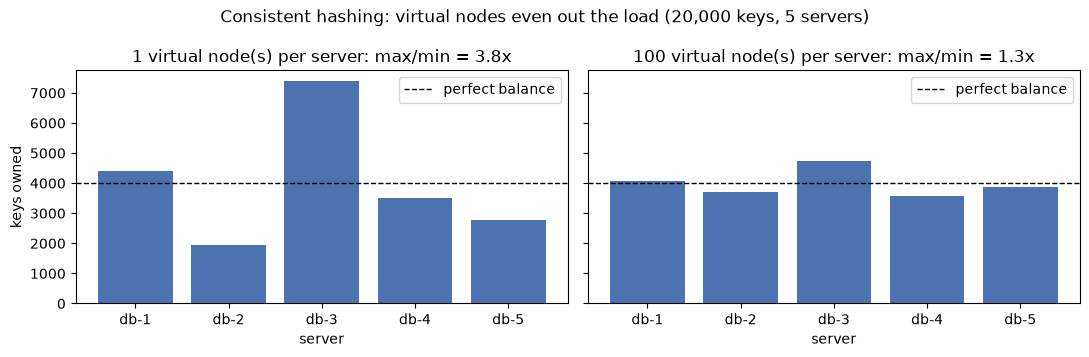

In [11]:
# Load balance with 1 vs 100 virtual nodes per server
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, v in zip(axes, [1, 100]):
    r = ConsistentHashRing(nodes4 + ["db-5"], vnodes=v)
    load = Counter(r.lookup(k) for k in keys)
    counts = [load[n] for n in sorted(load)]
    ax.bar(sorted(load), counts, color="#4C72B0")
    ax.axhline(len(keys) / 5, color="black", ls="--", lw=1, label="perfect balance")
    ax.set_title(f"{v} virtual node(s) per server: max/min = {max(counts) / max(min(counts), 1):.1f}x")
    ax.set_xlabel("server"); ax.legend()
axes[0].set_ylabel("keys owned")
plt.suptitle("Consistent hashing: virtual nodes even out the load (20,000 keys, 5 servers)")
plt.tight_layout(); plt.show()

**What just happened?** With mod-N hashing roughly 80% of the keys changed server; with consistent hashing only about one
fifth did, and every one of them moved *to the new server* (none were shuffled between old servers). With a single position
per server the load is very uneven (one server can own several times as many keys as another); with 100 virtual nodes each
server owns close to 20%.

**Complexity.** `lookup` is a binary search over $N \cdot V$ ring positions: $O(\log (NV))$ time; the ring uses $O(NV)$ space.
Adding a node costs $O(V \log(NV))$ to update the ring plus moving $\approx K/(N+1)$ of the $K$ keys.

Used by: Amazon Dynamo and Cassandra (token ring), Riak, memcached client libraries, CDN and load-balancer routing.
Related alternatives: **rendezvous (highest-random-weight) hashing** and **jump consistent hash**.

> ⚠️ **Common mistake.** Using Python's built-in `hash()` for sharding: string hashing is randomised per process
> (`PYTHONHASHSEED`), so two servers would disagree on where a key lives. Use a stable hash (md5, xxhash, murmur3).

---
## 9. Data warehousing: OLTP vs OLAP and architecture

> **In plain English:** the everyday database takes orders; the warehouse keeps history in a shape that makes big questions easy.

**Analogy.** A supermarket's tills (OLTP) record each sale in milliseconds. The head office (OLAP) wants "*sales by region by
month for the last three years, compared with last year*". Running that on the tills' database would slow down the checkout,
and the tills only keep recent, detailed data anyway. So the company copies the data every night into a separate system built
for analysis: the **data warehouse**.

**Definition (W. H. Inmon).** A **data warehouse** is a *subject-oriented, integrated, time-variant and non-volatile* collection of
data in support of management's decision-making process.
- **Subject-oriented**: organised around business subjects (sales, customers), not around applications.
- **Integrated**: data from many sources with consistent names, codes and units.
- **Time-variant**: keeps history (years), every row is tied to a point or period in time.
- **Non-volatile**: loaded and read; not updated in place by transactions.

| | **OLTP** (online transaction processing) | **OLAP** (online analytical processing) |
|---|---|---|
| Users | customers, clerks, applications (many, concurrent) | analysts, managers, data scientists, dashboards |
| Typical query | read/write a few rows by key | scan and aggregate millions of rows |
| Data | current, detailed | historical, integrated, often summarised |
| Schema | normalised (3NF/BCNF) to avoid update anomalies | denormalised **dimensional** (star) for simple, fast queries |
| Workload | many short transactions, ACID critical | few long read-only queries, bulk loads |
| Storage layout | row store, B+ tree indexes | **column store**, compression, partitioning, MPP |
| Size | GB to a few TB | TB to PB |
| Examples | PostgreSQL, MySQL, Oracle, SQL Server | Snowflake, BigQuery, Redshift, ClickHouse, DuckDB, Databricks SQL |

### Warehouse architecture

```
  SOURCES                 INTEGRATION              STORAGE                       CONSUMPTION
 ┌──────────────┐       ┌───────────────┐      ┌─────────────────────┐      ┌───────────────────┐
 │ OLTP DBs     │──┐    │ ETL: extract, │      │ staging area         │      │ BI dashboards     │
 │ CRM / ERP    │──┼──► │ transform,    │ ───► │ enterprise data      │ ───► │ (Power BI, Looker,│
 │ web logs     │──┤    │ load          │      │ warehouse (history)  │      │  Tableau, Superset)│
 │ CSV / APIs   │──┘    │ or ELT: load  │      │   │                  │      │ ad-hoc SQL        │
 └──────────────┘       │ raw, transform│      │   ├─► data mart: sales│ ───► │ ML training sets  │
                        │ inside the DW │      │   ├─► data mart: HR  │      │ reports, OLAP     │
                        └───────────────┘      │   └─► data mart: fin. │      └───────────────────┘
                     metadata + data quality   └─────────────────────┘
```

- **ETL** transforms before loading (classic, on a separate ETL server); **ELT** loads raw data first and transforms with SQL
  inside the warehouse (modern cloud warehouses + dbt). See [`../06_data_engineering/01_data_engineering.ipynb`](../06_data_engineering/01_data_engineering.ipynb).
- **Inmon (top-down)**: build a normalised enterprise warehouse first, then derive data marts from it.
  **Kimball (bottom-up)**: build dimensional data marts per business process, tied together by **conformed dimensions**
  (the same `dim_date`, `dim_product` used everywhere) on a "bus architecture".
- The **medallion** (bronze/silver/gold) layering of lakehouses is the same idea with different names; see
  [`../../22_ML_System_Design/04_nosql_and_data_stores.ipynb`](../../22_ML_System_Design/04_nosql_and_data_stores.ipynb).

---
## 10. Dimensional modelling: star, snowflake, galaxy

> **In plain English:** put the numbers you measure (sales) in one central table and the descriptions (when, where, what) in tables around it.

**Dimensional modelling** (Ralph Kimball) organises analytical data into:
- **Fact tables**: one row per *measurement event* at a declared **grain** (e.g. "one row per product line in a sales receipt").
  Columns are foreign keys to dimensions plus numeric **measures**.
  Measures are **additive** (sum over any dimension: `sales_amount`), **semi-additive** (sum over some dimensions but not time:
  `stock_on_hand`, account balance) or **non-additive** (never summed: ratios, unit price, percentages).
- **Dimension tables**: the *context*: who, what, where, when. Wide, descriptive, denormalised, with a **surrogate key**
  (a meaningless integer) and the source system's **natural key**.

The four design steps (Kimball): **(1) choose the business process, (2) declare the grain, (3) identify the dimensions,
(4) identify the facts.**

| Schema | Shape | Pros | Cons |
|---|---|---|---|
| **Star** | one fact table, each dimension is one denormalised table | simplest SQL, fewest joins, fast | redundancy in dimensions (category repeated per product) |
| **Snowflake** | dimensions normalised into sub-dimensions (product → subcategory → category) | less redundancy, easier dimension maintenance | more joins, harder for BI users |
| **Galaxy / fact constellation** | several fact tables sharing (conformed) dimensions | models several business processes together | more complex |

We build a small retail warehouse in SQLite: ~18 months of sales in 6 stores, star and snowflake versions, plus an
inventory fact table to form a galaxy.

In [12]:
dw = sqlite3.connect(":memory:")            # the warehouse

# ---------- dimensions ----------
dates = pd.date_range("2025-01-01", "2026-06-30", freq="D")
dim_date = pd.DataFrame({
    "date_key": dates.strftime("%Y%m%d").astype(int),       # smart key 20250101: readable and sortable
    "full_date": dates.strftime("%Y-%m-%d"),
    "day_name": dates.day_name(),
    "month": dates.month, "month_name": dates.month_name(),
    "quarter": dates.quarter, "year": dates.year,
    "is_weekend": (dates.dayofweek >= 5).astype(int),
})
stores = [("S1", "Lahore", "Punjab", "North"), ("S2", "Rawalpindi", "Punjab", "North"),
          ("S3", "Islamabad", "ICT", "North"), ("S4", "Karachi", "Sindh", "South"),
          ("S5", "Hyderabad", "Sindh", "South"), ("S6", "Quetta", "Balochistan", "South")]
dim_store = pd.DataFrame(stores, columns=["store_code", "city", "province", "region"])
dim_store.insert(0, "store_key", range(1, len(dim_store) + 1))
catalog = {"Electronics": {"Phones": 220, "Accessories": 15}, "Books": {"Fiction": 8, "Textbooks": 25},
           "Grocery": {"Snacks": 2, "Beverages": 3}}
prod_rows = []
for cat, subs in catalog.items():
    for sub, base_price in subs.items():
        for j in range(5):                                        # 5 products per subcategory -> 30 products
            prod_rows.append((f"{sub[:3].upper()}-{j+1}", f"{sub} item {j+1}", sub, cat,
                              round(base_price * (0.8 + 0.1 * j), 2)))
dim_product = pd.DataFrame(prod_rows, columns=["sku", "product_name", "subcategory", "category", "list_price"])
dim_product.insert(0, "product_key", range(1, len(dim_product) + 1))
n_customers = 800
dim_customer = pd.DataFrame({"customer_key": range(1, n_customers + 1),
                             "customer_id": [f"C{i:04d}" for i in range(1, n_customers + 1)],
                             "segment": rng.choice(["Regular", "Loyalty", "Corporate"], n_customers, p=[0.6, 0.3, 0.1])})

# ---------- fact_sales: grain = one product line on one receipt (basket) ----------
n_baskets = 6_000
basket_dates = rng.choice(dim_date.date_key.values, n_baskets)
basket_store = rng.choice(dim_store.store_key.values, n_baskets, p=[0.25, 0.1, 0.15, 0.3, 0.1, 0.1])
basket_cust = rng.integers(1, n_customers + 1, n_baskets)
lines = []
pop = rng.dirichlet(np.ones(len(dim_product)) * 0.7)             # some products are much more popular
for b in range(n_baskets):
    n_items = rng.integers(1, 5)                                  # 1-4 distinct products per basket
    for pk in rng.choice(dim_product.product_key.values, n_items, replace=False, p=pop):
        qty = int(rng.integers(1, 4))
        price = float(dim_product.list_price.iloc[pk - 1])
        lines.append((b + 1, int(basket_dates[b]), int(basket_store[b]), int(pk), int(basket_cust[b]), qty, price,
                      round(qty * price, 2)))
fact_sales = pd.DataFrame(lines, columns=["basket_id", "date_key", "store_key", "product_key", "customer_key",
                                          "quantity", "unit_price", "sales_amount"])

for name, df in {"dim_date": dim_date, "dim_store": dim_store, "dim_product": dim_product,
                 "dim_customer": dim_customer, "fact_sales": fact_sales}.items():
    df.to_sql(name, dw, index=False)
print({t: dw.execute(f"select count(*) from {t}").fetchone()[0] for t in
       ["dim_date", "dim_store", "dim_product", "dim_customer", "fact_sales"]})
print(fact_sales.head(3).to_string(index=False))

{'dim_date': 546, 'dim_store': 6, 'dim_product': 30, 'dim_customer': 800, 'fact_sales': 15058}
 basket_id  date_key  store_key  product_key  customer_key  quantity  unit_price  sales_amount
         1  20250921          5           30           165         3         3.6          10.8
         1  20250921          5           16           165         3        20.0          60.0
         1  20250921          5            7           165         1        13.5          13.5


`basket_id` is a **degenerate dimension**: an identifier kept in the fact table with no dimension table of its own (like an
invoice number). `unit_price` is **non-additive** (never sum it), `quantity` and `sales_amount` are **additive**.

Now the **snowflake** version of the product and store dimensions, and a second fact table, `fact_inventory`
(grain: one product in one store at the end of one month; `stock_on_hand` is **semi-additive**). Together with
`fact_sales` it forms a **galaxy** that shares the conformed dimensions `dim_date`, `dim_store`, `dim_product`.

In [13]:
# ---------- SNOWFLAKE: normalise product -> subcategory -> category, store -> province -> region ----------
dw.executescript("""
create table sf_category    as select row_number() over (order by category) as category_key, category
                               from (select distinct category from dim_product);
create table sf_subcategory as select row_number() over (order by subcategory) as subcategory_key, d.subcategory,
                                      c.category_key
                               from (select distinct subcategory, category from dim_product) d
                               join sf_category c using (category);
create table sf_product     as select p.product_key, p.sku, p.product_name, s.subcategory_key, p.list_price
                               from dim_product p join sf_subcategory s using (subcategory);
create table sf_region      as select row_number() over (order by region) as region_key, region
                               from (select distinct region from dim_store);
create table sf_province    as select row_number() over (order by province) as province_key, d.province, r.region_key
                               from (select distinct province, region from dim_store) d join sf_region r using (region);
create table sf_store       as select s.store_key, s.store_code, s.city, p.province_key
                               from dim_store s join sf_province p using (province);
""")

# ---------- GALAXY: a second fact table sharing the dimensions ----------
month_ends = dim_date.groupby(["year", "month"]).date_key.max().values      # last day of every month
inv = [(int(d), int(s), int(p), int(rng.integers(0, 200)))
       for d in month_ends for s in dim_store.store_key for p in dim_product.product_key]
pd.DataFrame(inv, columns=["date_key", "store_key", "product_key", "stock_on_hand"]).to_sql("fact_inventory", dw, index=False)

star_sql = """
select p.category, round(sum(f.sales_amount), 2) as revenue
from fact_sales f join dim_product p on p.product_key = f.product_key
group by p.category order by p.category"""
snow_sql = """
select c.category, round(sum(f.sales_amount), 2) as revenue
from fact_sales f
join sf_product p     on p.product_key = f.product_key
join sf_subcategory s on s.subcategory_key = p.subcategory_key
join sf_category c    on c.category_key = s.category_key
group by c.category order by c.category"""
star_res, snow_res = pd.read_sql(star_sql, dw), pd.read_sql(snow_sql, dw)
print("Star schema (1 join):\n", star_res.to_string(index=False))
print("Snowflake schema (3 joins) gives the same answer:", star_res.equals(snow_res))
assert star_res.equals(snow_res)
assert abs(star_res.revenue.sum() - fact_sales.sales_amount.sum()) < 0.01
print("fact_inventory rows:", dw.execute("select count(*) from fact_inventory").fetchone()[0])

Star schema (1 join):
    category   revenue
      Books  115163.6
Electronics 1373028.5
    Grocery   32209.2
Snowflake schema (3 joins) gives the same answer: True
fact_inventory rows: 3240


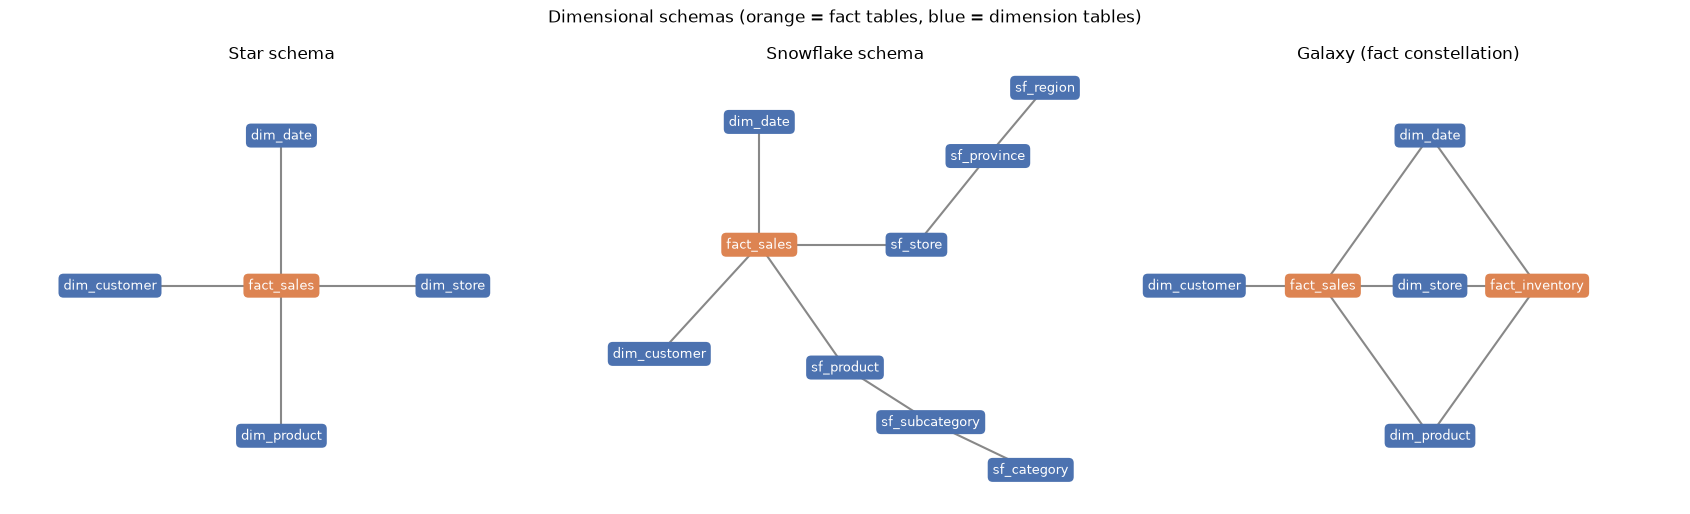

In [14]:
def draw_schema(ax, edges, pos, facts, title):
    """Draw a schema: facts in orange boxes, dimensions in blue boxes; lines are foreign-key references."""
    g = nx.Graph(edges)
    nx.draw_networkx_edges(g, pos, ax=ax, edge_color="#888888", width=1.5)
    for n, (x, y) in pos.items():
        ax.text(x, y, n, ha="center", va="center", fontsize=9, color="white",
                bbox=dict(boxstyle="round,pad=0.4", fc="#DD8452" if n in facts else "#4C72B0", ec="none"))
    ax.set_xlim(-1.9, 1.9); ax.set_ylim(-1.6, 1.6); ax.set_title(title); ax.axis("off")


fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
star = [("fact_sales", d) for d in ["dim_date", "dim_store", "dim_product", "dim_customer"]]
star_pos = {"fact_sales": (0, 0), "dim_date": (0, 1.1), "dim_store": (1.2, 0), "dim_product": (0, -1.1),
            "dim_customer": (-1.2, 0)}
snow = [("fact_sales", "dim_date"), ("fact_sales", "sf_store"), ("fact_sales", "sf_product"),
        ("fact_sales", "dim_customer"), ("sf_product", "sf_subcategory"), ("sf_subcategory", "sf_category"),
        ("sf_store", "sf_province"), ("sf_province", "sf_region")]
snow_pos = {"fact_sales": (-0.6, 0.3), "dim_date": (-0.6, 1.2), "dim_customer": (-1.3, -0.5),
            "sf_store": (0.5, 0.3), "sf_province": (1.0, 0.95), "sf_region": (1.4, 1.45),
            "sf_product": (0.0, -0.6), "sf_subcategory": (0.6, -1.0), "sf_category": (1.3, -1.35)}
galaxy = star + [("fact_inventory", d) for d in ["dim_date", "dim_store", "dim_product"]]
gal_pos = {"fact_sales": (-0.6, 0), "fact_inventory": (0.9, 0), "dim_date": (0.15, 1.1), "dim_store": (0.15, 0),
           "dim_product": (0.15, -1.1), "dim_customer": (-1.5, 0)}
draw_schema(axes[0], star, star_pos, {"fact_sales"}, "Star schema")
draw_schema(axes[1], snow, snow_pos, {"fact_sales"}, "Snowflake schema")
draw_schema(axes[2], galaxy, gal_pos, {"fact_sales", "fact_inventory"}, "Galaxy (fact constellation)")
plt.suptitle("Dimensional schemas (orange = fact tables, blue = dimension tables)")
plt.tight_layout(); plt.show()

**What just happened?** The star query needs one join to group revenue by category; the snowflake query needs three joins
for exactly the same answer (asserted). In the galaxy, `dim_date`, `dim_store` and `dim_product` are **conformed
dimensions** shared by two fact tables, so you can compare sales with stock levels using the same filters.

The semi-additive trap: summing `stock_on_hand` across stores on one date is fine; summing it across *months* is
meaningless (you would count the same box of stock 18 times). Use the last value (or the average) over time:

In [15]:
semi = pd.read_sql("""
select 'sum over months (WRONG)'      as method, sum(stock_on_hand) as stock from fact_inventory where product_key = 1
union all
select 'value at last month-end (OK)', sum(stock_on_hand) from fact_inventory
 where product_key = 1 and date_key = (select max(date_key) from fact_inventory)
""", dw)
print(semi.to_string(index=False))
assert semi.stock[0] > 10 * semi.stock[1]

                      method  stock
     sum over months (WRONG)  10346
value at last month-end (OK)    595


---
## 11. Slowly changing dimensions

> **In plain English:** when a customer moves city, decide whether old sales should still count for the old city (usually yes).

Dimension attributes change over time: a customer moves city, a product changes category. A **slowly changing dimension
(SCD)** strategy decides what history to keep.

| Type | What happens on a change | History? | Example use |
|---|---|---|---|
| **0** | keep the original value forever | n/a | date of birth, original sign-up channel |
| **1** | **overwrite** the old value | none: old facts now show the new value | fixing typos, attributes nobody analyses historically |
| **2** | **add a new row** with a new surrogate key; mark validity with `valid_from`, `valid_to`, `is_current` | full | customer city, sales territory, price tier |
| **3** | add a "previous value" column | one previous version only | a one-time reorganisation |
| **4 / 6** | history table (type 4); hybrid of 1+2+3 (type 6) | full | large, fast-changing dimensions |

Worked example: customer **C0007** lives in Lahore, moves to Karachi on 2026-01-01. She bought Rs 100 + Rs 200 in 2025 and
Rs 50 + Rs 80 in 2026. The business question: *revenue by the customer's city at the time of purchase*.

| Approach | Lahore revenue | Karachi revenue |
|---|---|---|
| Correct history | 300 | 130 |
| Type 1 (overwrite) | 0 | 430 (history rewritten) |
| Type 2 (new row) | 300 | 130 |

In [16]:
scd = sqlite3.connect(":memory:")
scd.executescript("""
create table dim_customer_t1 (customer_id text primary key, city text);
create table dim_customer_t2 (
    customer_key integer primary key,      -- surrogate key: a new one for every version
    customer_id  text not null,            -- natural (business) key
    city         text not null,
    valid_from   text not null,
    valid_to     text not null default '9999-12-31',   -- open-ended for the current row
    is_current   integer not null default 1
);
create table sales (sale_date text, customer_id text, amount real, customer_key integer);
insert into dim_customer_t1 values ('C0007', 'Lahore'), ('C0008', 'Quetta');
insert into dim_customer_t2 (customer_id, city, valid_from) values ('C0007', 'Lahore', '2024-03-01'),
                                                                  ('C0008', 'Quetta', '2024-05-01');
""")


def scd2_apply(conn, customer_id, new_city, effective_date):
    """Type 2 change: close the current row and insert a new version (in ONE transaction)."""
    with conn:                                                    # commit both statements or neither
        cur = conn.execute("select city from dim_customer_t2 where customer_id = ? and is_current = 1",
                           (customer_id,)).fetchone()
        if cur is None or cur[0] == new_city:
            return                                                # nothing to do (idempotent)
        conn.execute("""update dim_customer_t2 set valid_to = ?, is_current = 0
                        where customer_id = ? and is_current = 1""", (effective_date, customer_id))
        conn.execute("insert into dim_customer_t2 (customer_id, city, valid_from) values (?, ?, ?)",
                     (customer_id, new_city, effective_date))


def load_sale(conn, sale_date, customer_id, amount):
    """Fact loading: look up the surrogate key of the version valid ON THE SALE DATE."""
    key = conn.execute("""select customer_key from dim_customer_t2
                         where customer_id = ? and ? >= valid_from and ? < valid_to""",
                       (customer_id, sale_date, sale_date)).fetchone()[0]
    conn.execute("insert into sales values (?, ?, ?, ?)", (sale_date, customer_id, amount, key))


load_sale(scd, "2025-04-10", "C0007", 100); load_sale(scd, "2025-11-02", "C0007", 200)
scd2_apply(scd, "C0007", "Karachi", "2026-01-01")                                   # she moves
scd.execute("update dim_customer_t1 set city = 'Karachi' where customer_id = 'C0007'")  # type 1: overwrite
load_sale(scd, "2026-02-14", "C0007", 50); load_sale(scd, "2026-05-20", "C0007", 80)
scd2_apply(scd, "C0007", "Karachi", "2026-06-01")                                   # repeated change: no-op

print(pd.read_sql("select * from dim_customer_t2", scd).to_string(index=False))
t1 = pd.read_sql("""select d.city, sum(s.amount) as revenue from sales s
                     join dim_customer_t1 d using (customer_id) group by d.city""", scd)
t2 = pd.read_sql("""select d.city, sum(s.amount) as revenue from sales s
                     join dim_customer_t2 d using (customer_key) group by d.city order by d.city""", scd)
print("\nType 1 report:\n", t1.to_string(index=False))
print("\nType 2 report:\n", t2.to_string(index=False))

assert dict(zip(t1.city, t1.revenue)) == {"Karachi": 430.0}
assert dict(zip(t2.city, t2.revenue)) == {"Karachi": 130.0, "Lahore": 300.0}
# SCD2 invariants: exactly one current row per natural key; validity intervals do not overlap
assert scd.execute("""select max(c) from (select count(*) c from dim_customer_t2
                       where is_current = 1 group by customer_id)""").fetchone()[0] == 1
overlaps = scd.execute("""select count(*) from dim_customer_t2 a join dim_customer_t2 b
                           on a.customer_id = b.customer_id and a.customer_key < b.customer_key
                           and a.valid_from < b.valid_to and b.valid_from < a.valid_to""").fetchone()[0]
assert overlaps == 0

 customer_key customer_id    city valid_from   valid_to  is_current
            1       C0007  Lahore 2024-03-01 2026-01-01           0
            2       C0008  Quetta 2024-05-01 9999-12-31           1
            3       C0007 Karachi 2026-01-01 9999-12-31           1

Type 1 report:
    city  revenue
Karachi    430.0

Type 2 report:
    city  revenue
Karachi    130.0
 Lahore    300.0


**What just happened?** Type 1 rewrote history: all Rs 430 now appear under Karachi. Type 2 kept both versions of C0007,
each fact row points at the version that was valid on the sale date, so the report matches reality (300 / 130).
The repeated "move to Karachi" was a no-op, which makes the loader **idempotent** (safe to re-run), an important property of
real ETL jobs.

> ⚠️ **Common mistake.** Joining facts to a type 2 dimension on the **natural key** (`customer_id`) instead of the surrogate key.
> Every sale then matches *every* version of the customer, and revenue is double-counted. Either store the surrogate key
> in the fact table at load time (as above) or join with the date condition `sale_date >= valid_from and sale_date < valid_to`.

---
## 12. OLAP operations

> **In plain English:** zoom out, zoom in, cut a slice, cut a smaller cube, or turn the table sideways: five ways to look at the same numbers.

Think of the facts as a **data cube**: each dimension is an axis (time, store, product), each cell holds a measure
(revenue). The five classic operations:

| Operation | Meaning | SQL idea |
|---|---|---|
| **Roll-up** (drill-up) | go up a hierarchy (day → month → quarter → year) or drop a dimension | coarser `GROUP BY`; `ROLLUP` |
| **Drill-down** | the reverse: more detail (year → quarter → month) | finer `GROUP BY` |
| **Slice** | fix **one** dimension to a single value, giving a sub-cube with one fewer dimension | `WHERE category = 'Books'` |
| **Dice** | select a sub-cube with conditions on **two or more** dimensions | `WHERE region='North' AND year=2026 AND category IN (...)` |
| **Pivot** (rotate) | swap rows and columns of the result for a different view | `CASE WHEN` columns / `pandas.pivot_table` |

```
             product ─►                    Slice: category = Books        Dice: North stores,
        ┌────┬────┬────┐                   ┌────┬────┐                     2026, Electronics+Books
 time   │    │    │    │ ◄─ store (depth)   │    │    │ (time × store)     ┌────┐
   │    ├────┼────┼────┤                   ├────┼────┤                     │    │ small sub-cube
   ▼    │    │    │    │                   │    │    │                     └────┘
        └────┴────┴────┘                   └────┴────┘
```

PostgreSQL, SQL Server, Oracle, BigQuery, Snowflake and DuckDB support `GROUP BY ROLLUP(...)`, `CUBE(...)` and
`GROUPING SETS(...)`. SQLite does not, so we emulate them with `UNION ALL`, which also shows what they mean.

In [17]:
SALES = """from fact_sales f join dim_date d using (date_key) join dim_store s using (store_key)
            join dim_product p using (product_key)"""

# ---- ROLL-UP: month -> quarter -> year -> grand total, emulating GROUP BY ROLLUP(year, quarter, month) ----
rollup = pd.read_sql(f"""
select * from (
select year, quarter, month, round(sum(sales_amount), 2) as revenue {SALES} group by year, quarter, month
union all
select year, quarter, null, round(sum(sales_amount), 2) {SALES} group by year, quarter
union all
select year, null, null, round(sum(sales_amount), 2) {SALES} group by year
union all
select null, null, null, round(sum(sales_amount), 2) {SALES}
)
order by year is null, year, quarter is null, quarter, month is null, month""", dw)
rollup[["year", "quarter", "month"]] = rollup[["year", "quarter", "month"]].astype("Int64")   # show 2026, not 2026.0
print("ROLL-UP (<NA> is SQL NULL, meaning 'all'), rows for 2026 and the grand total:")
print(rollup[(rollup.year == 2026) | rollup.year.isna()].to_string(index=False))

# consistency of the roll-up: months sum to quarters, quarters to years, years to the grand total
months = rollup.dropna(subset=["month"])
quarters = rollup[rollup.month.isna() & rollup.quarter.notna()]
years = rollup[rollup.quarter.isna() & rollup.year.notna()]
grand = rollup[rollup.year.isna()].revenue.iloc[0]
assert np.allclose(months.groupby(["year", "quarter"]).revenue.sum().values, quarters.revenue.values, atol=0.05)
assert np.isclose(years.revenue.sum(), grand, atol=0.05) and np.isclose(grand, fact_sales.sales_amount.sum(), atol=0.05)

ROLL-UP (<NA> is SQL NULL, meaning 'all'), rows for 2026 and the grand total:
 year  quarter  month   revenue
 2026        1      1   75127.2
 2026        1      2   72905.7
 2026        1      3   93115.0
 2026        1   <NA>  241147.9
 2026        2      4   89158.4
 2026        2      5   82186.4
 2026        2      6   79354.1
 2026        2   <NA>  250698.9
 2026     <NA>   <NA>  491846.8
 <NA>     <NA>   <NA> 1520401.3


In [18]:
# ---- DRILL-DOWN: 2025 by quarter, then Q4 2025 by month, then December 2025 by region ----
q = pd.read_sql(f"select quarter, round(sum(sales_amount),2) revenue {SALES} where year = 2025 group by quarter", dw)
m = pd.read_sql(f"select month_name, round(sum(sales_amount),2) revenue {SALES} where year = 2025 and quarter = 4 "
                f"group by month order by month", dw)
r = pd.read_sql(f"select region, round(sum(sales_amount),2) revenue {SALES} where year = 2025 and month = 12 "
                f"group by region", dw)
print("2025 by quarter:\n", q.to_string(index=False), "\n\nQ4 2025 by month:\n", m.to_string(index=False),
      "\n\nDecember 2025 by region:\n", r.to_string(index=False))
assert np.isclose(m.revenue.sum(), q[q.quarter == 4].revenue.iloc[0], atol=0.05)
assert np.isclose(r.revenue.sum(), m.revenue.iloc[-1], atol=0.05)

# ---- SLICE: category = 'Books' -> a 2-D (region x year) sub-cube ----
slice_df = pd.read_sql(f"""select region, year, round(sum(sales_amount),2) revenue {SALES}
                            where category = 'Books' group by region, year""", dw)
print("\nSLICE category = Books:\n", slice_df.to_string(index=False))

# ---- DICE: North region AND year 2026 AND category in (Electronics, Books) ----
dice_df = pd.read_sql(f"""select city, category, round(sum(sales_amount),2) revenue {SALES}
                           where region = 'North' and year = 2026 and category in ('Electronics','Books')
                           group by city, category order by city, category""", dw)
print("\nDICE (North, 2026, Electronics+Books):\n", dice_df.to_string(index=False))
# the same dice with pandas, as an independent check
flat = (fact_sales.merge(dim_date, on="date_key").merge(dim_store, on="store_key").merge(dim_product, on="product_key"))
chk = (flat[(flat.region == "North") & (flat.year == 2026) & flat.category.isin(["Electronics", "Books"])]
       .groupby(["city", "category"]).sales_amount.sum().round(2).reset_index())
assert np.allclose(chk.sales_amount.values, dice_df.revenue.values)

2025 by quarter:
  quarter  revenue
       1 259130.6
       2 248843.1
       3 272065.3
       4 248515.5 

Q4 2025 by month:
 month_name  revenue
   October  73306.4
  November  85705.5
  December  89503.6 

December 2025 by region:
 region  revenue
 North  50567.2
 South  38936.4

SLICE category = Books:
 region  year  revenue
 North  2025  38443.2
 North  2026  18261.8
 South  2025  39081.4
 South  2026  19377.2

DICE (North, 2026, Electronics+Books):
       city    category  revenue
 Islamabad       Books   5225.8
 Islamabad Electronics  72887.0
    Lahore       Books   9117.6
    Lahore Electronics 119955.5
Rawalpindi       Books   3918.4
Rawalpindi Electronics  38704.5


              2025-Q1   2025-Q2   2025-Q3   2025-Q4   2026-Q1   2026-Q2
category                                                               
Books         20247.1   18221.0   19783.1   19273.4   20183.2   17455.8
Electronics  233046.5  225557.5  246708.5  224087.5  215424.0  228204.5
Grocery        5837.0    5064.6    5573.7    5154.6    5540.7    5038.6
SQL pivot == pandas pivot_table: True


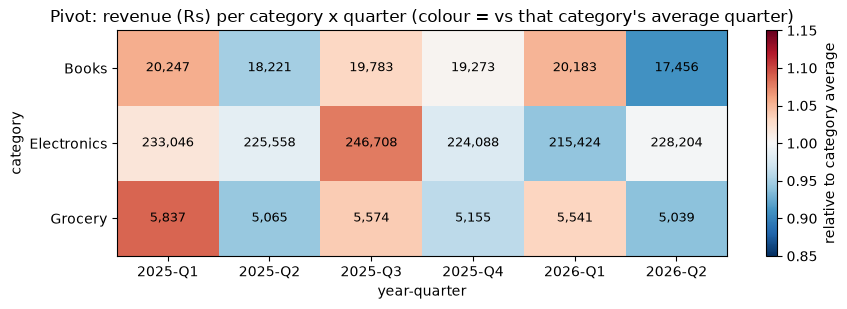

In [19]:
# ---- PIVOT: categories as rows, quarters as columns ----
# (a) SQL: conditional aggregation
pivot_sql = pd.read_sql(f"""
select category,
       round(sum(case when year = 2025 and quarter = 1 then sales_amount else 0 end), 2) as "2025-Q1",
       round(sum(case when year = 2025 and quarter = 2 then sales_amount else 0 end), 2) as "2025-Q2",
       round(sum(case when year = 2025 and quarter = 3 then sales_amount else 0 end), 2) as "2025-Q3",
       round(sum(case when year = 2025 and quarter = 4 then sales_amount else 0 end), 2) as "2025-Q4",
       round(sum(case when year = 2026 and quarter = 1 then sales_amount else 0 end), 2) as "2026-Q1",
       round(sum(case when year = 2026 and quarter = 2 then sales_amount else 0 end), 2) as "2026-Q2"
{SALES} group by category order by category""", dw).set_index("category")
# (b) pandas pivot_table on the flattened star
flat["yq"] = flat.year.astype(str) + "-Q" + flat.quarter.astype(str)
pivot_pd = flat.pivot_table(index="category", columns="yq", values="sales_amount", aggfunc="sum").round(2)
pivot_pd.columns.name = None
print(pivot_sql.to_string())
assert np.allclose(pivot_sql.values, pivot_pd[pivot_sql.columns].values, atol=0.05)
print("SQL pivot == pandas pivot_table: True")

rel = pivot_pd.div(pivot_pd.mean(axis=1), axis=0)          # each category relative to its own average quarter
fig, ax = plt.subplots(figsize=(9, 3.2))
im = ax.imshow(rel.values, cmap="RdBu_r", vmin=0.85, vmax=1.15, aspect="auto")
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        ax.text(j, i, f"{pivot_pd.values[i, j]:,.0f}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(rel.shape[1]), rel.columns); ax.set_yticks(range(rel.shape[0]), rel.index)
ax.set_xlabel("year-quarter"); ax.set_ylabel("category")
ax.set_title("Pivot: revenue (Rs) per category x quarter (colour = vs that category's average quarter)")
fig.colorbar(im, ax=ax, label="relative to category average")
plt.tight_layout(); plt.show()

**What just happened?** The roll-up result contains every level of the time hierarchy at once (`NULL` = "all"), and the asserts
confirm that months add up to quarters, quarters to years and years to the grand total. Drill-down went the other way
(year → quarter → month → region). The slice fixed one dimension; the dice restricted three; the pivot turned quarters into
columns, computed twice (SQL `CASE WHEN` and `pandas.pivot_table`) with identical results.

**Complexity.** Each aggregation is one scan of the fact table plus hash aggregation: $O(n)$ for $n$ fact rows. A full
`CUBE` over $d$ dimensions computes $2^d$ group-bys; that is why MOLAP engines pre-compute and why the
**"which aggregates to materialise"** problem (Harinarayan, Rajaraman & Ullman, 1996) is a classic.

> 🎓 **Exam tip.** *Slice* = one dimension fixed to one value. *Dice* = a range/set of values on two or more dimensions.
> Students often swap them.

---
## 13. ROLAP, MOLAP, HOLAP and data marts

> **In plain English:** store the summary numbers in normal tables, in a ready-made cube, or a mix of both; a data mart is one department's corner.

| | **ROLAP** (relational OLAP) | **MOLAP** (multidimensional OLAP) | **HOLAP** (hybrid) |
|---|---|---|---|
| Storage | star/snowflake tables in a relational DB | a pre-computed multidimensional array (cube) | detail in relational tables, aggregates in cubes |
| Query speed | depends on SQL engine (fast on modern column stores) | very fast for pre-computed aggregates | fast for summaries, slower drill to detail |
| Scalability | very high (just tables) | limited by cube size ($\prod$ of dimension sizes, sparsity) | high |
| Flexibility | any SQL, new dimensions easy | must rebuild the cube | in between |
| Examples | Snowflake, BigQuery, Redshift, ClickHouse behind BI tools | classic Essbase, SSAS multidimensional | SSAS (HOLAP mode), Apache Kylin-style aggregate stores |

Modern cloud warehouses are columnar, massively parallel engines, so most new systems are effectively ROLAP, often with
**materialised views** or aggregate tables acting as small cubes.

The MOLAP idea in a few lines: a dense numpy array indexed by (store, product, month); slices and roll-ups become array
indexing and `sum` along an axis.

In [20]:
months_idx = {k: i for i, k in enumerate(sorted({d // 100 for d in dim_date.date_key}))}   # 202501 -> 0, ...
cube = np.zeros((len(dim_store), len(dim_product), len(months_idx)))                      # 6 x 30 x 18 cells
for s, p, d, amt in fact_sales[["store_key", "product_key", "date_key", "sales_amount"]].itertuples(index=False):
    cube[s - 1, p - 1, months_idx[d // 100]] += amt                                        # pre-aggregate once
print("cube shape (store, product, month):", cube.shape, "| cells:", cube.size,
      "| non-empty:", f"{(cube > 0).mean():.0%}")
by_store = cube.sum(axis=(1, 2))                       # roll-up to store: sum over products and months
sql_by_store = pd.read_sql("select store_key, sum(sales_amount) r from fact_sales group by store_key order by store_key",
                           dw).r.values
assert np.allclose(by_store, sql_by_store)
print("MOLAP roll-up by store equals the ROLAP SQL result:", np.round(by_store, 0))

cube shape (store, product, month): (6, 30, 18) | cells: 3240 | non-empty: 72%
MOLAP roll-up by store equals the ROLAP SQL result: [393465. 139896. 231182. 452512. 157059. 146288.]


**What just happened?** After one pre-aggregation pass, any roll-up is a fast array reduction. But the cube has
$6 \times 30 \times 18$ cells for just three small dimensions; with realistic dimension sizes (millions of customers) a dense
cube explodes, which is MOLAP's scalability limit (real engines store sparse cubes and compress them).

**Data marts.** A **data mart** is a subject-specific subset of the warehouse for one department (sales, finance, HR).
- **Dependent** mart: fed from the enterprise warehouse (Inmon style) → consistent numbers.
- **Independent** mart: built directly from sources by one department → fast to build, but different departments end up with
  different "revenue" numbers ("data silos").
- **Kimball**: marts built per business process but sharing **conformed dimensions** so they can be combined.

---
## 14. Data mining and the KDD process

> **In plain English:** data mining finds useful patterns in data; it is one step of a longer process, and this repo's ML modules cover each step.

**Data mining** is the discovery of interesting, previously unknown and potentially useful patterns in large data sets.
Fayyad, Piatetsky-Shapiro & Smyth (1996) place it as **one step** of the larger **knowledge discovery in databases (KDD)**
process:

```
 data ──► Selection ──► Preprocessing ──► Transformation ──► Data mining ──► Interpretation / evaluation ──► knowledge
          (target data)  (cleaned data)    (features)          (patterns)      (validated, explained)
             ▲                                                                       │
             └──────────────────────────── iterate ◄─────────────────────────────────┘
```

| KDD step | What happens | Where it is in this repo |
|---|---|---|
| **Selection** | choose the relevant data (SQL on the warehouse, sampling) | [`../01_sql/01_sql_fundamentals.ipynb`](../01_sql/01_sql_fundamentals.ipynb), this notebook's star schema |
| **Preprocessing** | cleaning, missing values, duplicates, outliers | [`../../02_Data_Analysis/01_data_preprocessing.ipynb`](../../02_Data_Analysis/01_data_preprocessing.ipynb), [`../../02_Data_Analysis/07_eda.ipynb`](../../02_Data_Analysis/07_eda.ipynb) |
| **Transformation** | feature engineering, scaling, dimensionality reduction | [`../../03_Machine_Learning/05_feature_engineering/01_feature_engineering.ipynb`](../../03_Machine_Learning/05_feature_engineering/01_feature_engineering.ipynb), [`../../03_Machine_Learning/02_unsupervised/02_dimensionality_reduction.ipynb`](../../03_Machine_Learning/02_unsupervised/02_dimensionality_reduction.ipynb) |
| **Data mining** | classification, regression, clustering, association rules, anomaly detection | [`../../03_Machine_Learning/01_supervised/`](../../03_Machine_Learning/01_supervised/), [`../../03_Machine_Learning/02_unsupervised/01_clustering.ipynb`](../../03_Machine_Learning/02_unsupervised/01_clustering.ipynb), [`../../03_Machine_Learning/02_unsupervised/03_association_rules.ipynb`](../../03_Machine_Learning/02_unsupervised/03_association_rules.ipynb), [`../../03_Machine_Learning/08_anomaly_detection/01_anomaly_detection.ipynb`](../../03_Machine_Learning/08_anomaly_detection/01_anomaly_detection.ipynb) |
| **Interpretation / evaluation** | metrics, validation, explanation, deciding if a pattern is useful | [`../../03_Machine_Learning/06_model_evaluation/01_model_evaluation.ipynb`](../../03_Machine_Learning/06_model_evaluation/01_model_evaluation.ipynb), [`../../03_Machine_Learning/07_explainability/01_explainability.ipynb`](../../03_Machine_Learning/07_explainability/01_explainability.ipynb) |

The industry-standard process model **CRISP-DM** (1999–2000) adds the business side: business understanding → data
understanding → data preparation → modelling → evaluation → deployment.

A taste of mining *inside* the warehouse: the most frequent product-category pairs bought together, with **support**
(fraction of baskets containing both) and **confidence** $P(B \mid A)$, computed by a SQL self-join on the degenerate
`basket_id` dimension. (The full Apriori algorithm is in the association-rules notebook linked above.)

In [21]:
pairs = pd.read_sql("""
with basket_sub as (                                  -- one row per (basket, subcategory)
    select distinct f.basket_id, p.subcategory from fact_sales f join dim_product p using (product_key)
),
n as (select count(distinct basket_id) as baskets from fact_sales),
single as (select subcategory, count(*) as cnt from basket_sub group by subcategory)
select a.subcategory as A, b.subcategory as B,
       count(*) as together,
       round(1.0 * count(*) / (select baskets from n), 3) as support,
       round(1.0 * count(*) / (select cnt from single where subcategory = a.subcategory), 3) as confidence_A_to_B
from basket_sub a join basket_sub b on a.basket_id = b.basket_id and a.subcategory < b.subcategory
group by a.subcategory, b.subcategory order by together desc limit 5""", dw)
print(pairs.to_string(index=False))
# brute-force check of the top pair with pandas
bs = fact_sales.merge(dim_product, on="product_key")[["basket_id", "subcategory"]].drop_duplicates()
sets = bs.groupby("basket_id").subcategory.apply(set)
a0, b0 = pairs.A[0], pairs.B[0]
assert pairs.together[0] == sum(a0 in s and b0 in s for s in sets)

          A         B  together  support  confidence_A_to_B
  Beverages    Phones      1205    0.201              0.361
Accessories Beverages      1145    0.191              0.515
  Beverages   Fiction       973    0.162              0.292
  Beverages    Snacks       900    0.150              0.270
  Beverages Textbooks       849    0.141              0.255


**What just happened?** The SQL self-join counted, for every pair of subcategories, the baskets that contain both, and the
pandas brute force agrees for the top pair. (Our data is random, so the pairs mostly reflect product popularity; on real
data, high **lift** = confidence / support(B) is what reveals genuine associations.)

---
## 15. Big-data stores: HDFS, HBase, Hive, lakehouse

> **In plain English:** tools for data too big for one machine: a giant shared disk, a huge sorted key-value table, SQL on files, and files that behave like tables.

When data outgrows one machine (hundreds of TB), the Hadoop ecosystem (2006 onwards, modelled on Google's GFS, MapReduce and
Bigtable papers) and its successors spread storage and computation over clusters of commodity machines.

| System | What it is | Key facts |
|---|---|---|
| **HDFS** (Hadoop Distributed File System) | a distributed **file system** | files split into large **blocks** (128 MB by default) replicated on 3 DataNodes by default; a **NameNode** holds the metadata (which blocks make up which file, where they are); **write-once, read-many**: you can append but not update in the middle of a file; optimised for big sequential scans |
| **HBase** | a **wide-column** NoSQL store on top of HDFS, modelled on Google **Bigtable** | rows sorted by **row key**; columns grouped into **column families** (declared up front) whose **qualifiers** can differ per row; each cell keeps several **timestamped versions**; reads/writes of a single row are atomic and strongly consistent; tables split into **regions** served by RegionServers; no joins or SQL natively |
| **Hive** | SQL ("HiveQL") on files in HDFS / object storage | developed at Facebook; **schema-on-read**: a table is metadata over files; queries are compiled to distributed jobs (originally MapReduce, today usually Apache Tez); its **Hive Metastore** catalog is still used by Spark, Trino and others |
| **Lakehouse** | warehouse features (ACID, schema, SQL performance) directly on cheap object storage (S3, ADLS, GCS) | data in open columnar **Parquet** files + a **table format** (**Delta Lake**, **Apache Iceberg**, Apache Hudi) that keeps a transaction log / metadata tree, giving ACID commits, **time travel**, schema evolution and partition pruning; queried by Spark, Trino, Flink, DuckDB, Snowflake, BigQuery |

### HBase-style wide-column row vs an RDBMS row

In an RDBMS every row has every column (missing values are `NULL`). In HBase each row stores only the cells it has,
and each cell can keep several versions:

In [22]:
# RDBMS view: fixed schema, NULLs for absent values
rdbms = pd.DataFrame([
    {"user_id": "u001", "name": "Ali",  "city": "Lahore", "last_login": "2026-10-01", "fav_genre": None,   "premium_since": None},
    {"user_id": "u002", "name": "Sara", "city": None,     "last_login": "2026-10-20", "fav_genre": "jazz", "premium_since": "2025-02-01"},
])
print("RDBMS table (every column in every row):\n", rdbms.to_string(index=False))

# HBase view: row key -> {"family:qualifier": [(timestamp, value), ...newest first]}
hbase = defaultdict(lambda: defaultdict(list))


def put(row, column, value, ts):
    hbase[row][column].insert(0, (ts, value))         # newest version first, as HBase returns them


put("u001", "profile:name", "Ali", 1); put("u001", "profile:city", "Karachi", 2); put("u001", "profile:city", "Lahore", 5)
put("u001", "activity:last_login", "2026-10-01", 6)
put("u002", "profile:name", "Sara", 1); put("u002", "prefs:fav_genre", "jazz", 3)
put("u002", "activity:last_login", "2026-10-20", 7); put("u002", "billing:premium_since", "2025-02-01", 4)

for row in sorted(hbase):                              # HBase stores rows sorted by row key
    cells = {col: versions[0][1] for col, versions in sorted(hbase[row].items())}   # latest version of each cell
    print(row, "->", cells)
print("All versions of u001 profile:city:", hbase["u001"]["profile:city"])
assert hbase["u001"]["profile:city"][0][1] == "Lahore" and len(hbase["u001"]["profile:city"]) == 2
assert "prefs:fav_genre" not in hbase["u001"]          # absent cells are simply not stored (sparse)

RDBMS table (every column in every row):
 user_id name   city last_login fav_genre premium_since
   u001  Ali Lahore 2026-10-01      None          None
   u002 Sara   None 2026-10-20      jazz    2025-02-01
u001 -> {'activity:last_login': '2026-10-01', 'profile:city': 'Lahore', 'profile:name': 'Ali'}
u002 -> {'activity:last_login': '2026-10-20', 'billing:premium_since': '2025-02-01', 'prefs:fav_genre': 'jazz', 'profile:name': 'Sara'}
All versions of u001 profile:city: [(5, 'Lahore'), (2, 'Karachi')]


**What just happened?** The HBase rows store only the cells they have (no `NULL`s), columns can differ per row, and
`profile:city` keeps its history as timestamped versions. Because rows are sorted by key, **row-key design** is the most
important HBase decision (e.g. `userid#reverse_timestamp` to read a user's newest events with one short scan).

### How a lakehouse table format gets ACID on plain files

Object stores have no transactions, so Delta Lake and Iceberg add a **log of commits**. Data files are immutable; a commit
writes new files and then atomically adds one log entry (a JSON file in `_delta_log/` for Delta; a new metadata/snapshot
file for Iceberg) listing which files are now part of the table. Readers read only files listed in a committed version, so
they never see half-written data, and older versions remain readable (**time travel**). Here is that idea from scratch:

In [23]:
class MiniTableFormat:
    """A toy Delta/Iceberg: immutable data files + an ordered log of commits (versions)."""
    def __init__(self, root):
        self.root = root
        os.makedirs(os.path.join(root, "_log"), exist_ok=True)
        try:
            import pyarrow  # noqa: F401  (optional: real lakehouses use Parquet)
            self.fmt = "parquet"
        except ImportError:
            self.fmt = "csv"

    def _versions(self):
        return sorted(int(f.split(".")[0]) for f in os.listdir(os.path.join(self.root, "_log")))

    def commit(self, add_df=None, remove_files=()):
        v = (self._versions()[-1] + 1) if self._versions() else 0
        actions = {"remove": list(remove_files), "add": []}
        if add_df is not None:
            name = f"part-{v:05d}.{self.fmt}"
            path = os.path.join(self.root, name)
            add_df.to_parquet(path, index=False) if self.fmt == "parquet" else add_df.to_csv(path, index=False)
            actions["add"].append(name)                    # 1) write the data file (invisible to readers so far)
        log_path = os.path.join(self.root, "_log", f"{v:05d}.json")
        with open(log_path, "x") as fh:                    # 2) 'x' = create-only: two writers cannot both win version v
            json.dump(actions, fh)
        return v

    def files_at(self, version=None):
        live = []
        for v in self._versions():
            if version is not None and v > version:
                break
            with open(os.path.join(self.root, "_log", f"{v:05d}.json")) as fh:
                a = json.load(fh)
            live = [f for f in live if f not in a["remove"]] + a["add"]
        return live

    def read(self, version=None, columns=None):
        reader = (lambda p: pd.read_parquet(p, columns=columns)) if self.fmt == "parquet" else \
                 (lambda p: pd.read_csv(p, usecols=columns))
        files = self.files_at(version)
        return pd.concat([reader(os.path.join(self.root, f)) for f in files], ignore_index=True) if files else pd.DataFrame()


lake = MiniTableFormat(os.path.join(TMP, "sales_table"))
v0 = lake.commit(fact_sales.iloc[:10_000])                          # initial load
v1 = lake.commit(fact_sales.iloc[10_000:])                          # append the rest
fixed = lake.read(v1)
fixed = fixed[fixed.store_key != 6]                                 # "delete all rows for store 6" = rewrite + swap files
v2 = lake.commit(fixed, remove_files=lake.files_at(v1))
# a crashed writer: the data file exists, but no log entry was written -> readers never see it
fact_sales.head(5).to_csv(os.path.join(lake.root, "part-99999-orphan.csv"), index=False)

print("file format:", lake.fmt)
for v in [v0, v1, v2]:
    print(f"version {v}: files={lake.files_at(v)} rows={len(lake.read(v))}")
assert len(lake.read(v1)) == len(fact_sales) and len(lake.read(v0)) == 10_000
assert len(lake.read()) == (fact_sales.store_key != 6).sum()     # latest version
assert "part-99999-orphan.csv" not in lake.files_at()            # uncommitted file is invisible
cols = lake.read(columns=["sales_amount"])                         # columnar formats read only needed columns
print("read only one column:", list(cols.columns), "| time travel to v1 still works:", len(lake.read(v1)) == len(fact_sales))

file format: parquet
version 0: files=['part-00000.parquet'] rows=10000
version 1: files=['part-00000.parquet', 'part-00001.parquet'] rows=15058
version 2: files=['part-00002.parquet'] rows=13560
read only one column: ['sales_amount'] | time travel to v1 still works: True


**What just happened?** Every change created a new **version**; readers of version 1 still see all rows after the delete in
version 2 (time travel), and the orphan file of a "crashed" writer is ignored because no log entry points to it. Real table
formats add much more (optimistic concurrency with conflict checks, column statistics for data skipping, compaction,
vacuuming old files), but the core trick is exactly this: **immutable files + an atomic, ordered commit log**.
Parquet's columnar layout is also why reading one column is cheap: the other columns' bytes are never read.

> ⚠️ **Common mistake.** "A data lake is a lakehouse." A lake is just files (often a "data swamp" with no schema or
> transactions). A lakehouse adds a table format, a catalog and governance so the files behave like warehouse tables.

---
## 16. Database security

> **In plain English:** make sure only the right people can see and change the right data, and that nobody can trick or abuse the database.

Database security protects the **CIA triad**: **confidentiality** (no unauthorised reads), **integrity** (no unauthorised or
incorrect changes) and **availability** (authorised users can use the data when needed).

### 16.1 Authentication vs authorization

| | **Authentication** ("who are you?") | **Authorization** ("what may you do?") |
|---|---|---|
| Question | is this really user `alice`? | may `alice` run `UPDATE` on `salaries`? |
| Mechanisms | passwords (stored as salted slow hashes; PostgreSQL uses SCRAM-SHA-256), client certificates, Kerberos/LDAP, cloud IAM tokens, MFA | privileges (`GRANT`/`REVOKE`), roles (RBAC), views, row-level security, mandatory labels |
| Happens | once per connection / session | on every statement |

How a DBMS (or your app) should store passwords: never in plain text and never with a fast hash, but with a **salted, slow
key-derivation function** (bcrypt, scrypt, Argon2 or PBKDF2), compared in **constant time**:

In [24]:
def hash_password(password: str, salt: bytes = None, iterations: int = 100_000):
    """PBKDF2-HMAC-SHA256 from the standard library. (OWASP currently recommends 600,000 iterations; we use
    fewer to keep the notebook fast.) A random per-user salt makes identical passwords hash differently."""
    salt = salt or os.urandom(16)
    digest = hashlib.pbkdf2_hmac("sha256", password.encode(), salt, iterations)
    return salt, digest


def verify_password(password, salt, digest, iterations=100_000):
    return hmac.compare_digest(hashlib.pbkdf2_hmac("sha256", password.encode(), salt, iterations), digest)


salt_a, dig_a = hash_password("correct horse battery staple")
salt_b, dig_b = hash_password("correct horse battery staple")       # same password, different user
print("Same password, different salts -> different stored hashes:", dig_a != dig_b)
print("Right password accepted:", verify_password("correct horse battery staple", salt_a, dig_a))
print("Wrong password rejected:", not verify_password("Tr0ub4dor&3", salt_a, dig_a))
assert dig_a != dig_b and verify_password("correct horse battery staple", salt_a, dig_a)
assert not verify_password("Tr0ub4dor&3", salt_a, dig_a)

Same password, different salts -> different stored hashes: True
Right password accepted: True


Wrong password rejected: True


### 16.2 Authorization: GRANT, REVOKE and RBAC

SQLite has no users or privileges (it is an embedded library; access control is the file system's job), so here is the
standard SQL (PostgreSQL-flavoured) **as text**, followed by a from-scratch implementation of its rules.

```sql
-- Discretionary access control (DAC): owners grant privileges on their objects
GRANT SELECT, INSERT ON orders TO bob;                 -- privileges: SELECT, INSERT, UPDATE, DELETE, REFERENCES, ...
GRANT SELECT ON orders TO carol WITH GRANT OPTION;     -- carol may pass the privilege on
GRANT UPDATE (status) ON orders TO support_bot;        -- column-level privilege
REVOKE INSERT ON orders FROM bob;
REVOKE SELECT ON orders FROM carol CASCADE;            -- also removes grants carol made from it

-- Role-based access control (RBAC): privileges go to ROLES, users get roles
CREATE ROLE analyst;
GRANT SELECT ON sales, customers_masked TO analyst;
CREATE ROLE alice LOGIN PASSWORD '...';                -- in PostgreSQL a user is a role that can log in
GRANT analyst TO alice;
REVOKE analyst FROM alice;                             -- one statement when alice changes team

-- Views and row-level security restrict WHAT inside a table can be seen
CREATE VIEW customers_masked AS SELECT customer_id, city, segment FROM customers;   -- hides name, phone
ALTER TABLE orders ENABLE ROW LEVEL SECURITY;
CREATE POLICY tenant_isolation ON orders USING (tenant_id = current_setting('app.tenant_id')::int);
```

Other models: **MAC** (mandatory access control): objects and subjects get security labels (e.g. *Top Secret > Secret >
Unclassified*) and the **Bell–LaPadula** rules apply: *no read up* (simple security property) and *no write down*
(★-property). **ABAC** decides from attributes (department, time, location).

The trickiest rule is **cascading revoke**: a privilege granted by X must disappear when X loses the grant option, unless the
grantee also received it along another path from the owner. The code below implements the grant graph and a simple RBAC check.

In [25]:
class PrivilegeManager:
    """Grant graph for one privilege on one object, plus roles (RBAC). Owner holds everything implicitly."""
    def __init__(self, owner):
        self.owner = owner
        self.grants = set()                       # (grantor, grantee, with_grant_option)
        self.role_members = defaultdict(set)      # role -> users

    def has(self, user, need_grant_option=False):
        if user == self.owner:
            return True
        roles = {r for r, members in self.role_members.items() if user in members}
        return any(g == user or g in roles for (_, g, wgo) in self.grants if wgo or not need_grant_option)

    def grant(self, grantor, grantee, with_grant_option=False):
        if not self.has(grantor, need_grant_option=True):
            raise PermissionError(f"{grantor} cannot grant (no privilege WITH GRANT OPTION)")
        self.grants.add((grantor, grantee, with_grant_option))

    def revoke(self, grantor, grantee, cascade=True):
        self.grants = {g for g in self.grants if not (g[0] == grantor and g[1] == grantee)}
        if cascade:                               # remove grants whose grantor is no longer reachable from the owner
            changed = True
            while changed:
                supported = {self.owner}
                frontier = [self.owner]
                while frontier:                   # BFS over grant edges that carry the grant option
                    u = frontier.pop()
                    for (gr, ge, wgo) in self.grants:
                        if gr == u and wgo and ge not in supported:
                            supported.add(ge); frontier.append(ge)
                keep = {g for g in self.grants if g[0] in supported}
                changed = keep != self.grants
                self.grants = keep


pm = PrivilegeManager(owner="dba")
pm.grant("dba", "alice", with_grant_option=True)
pm.grant("dba", "carol", with_grant_option=True)
pm.grant("alice", "bob")                         # bob gets SELECT from alice...
pm.grant("carol", "bob")                         # ...and independently from carol
pm.grant("alice", "dave")                        # dave only via alice
pm.revoke("dba", "alice")                        # REVOKE ... FROM alice CASCADE
print("after revoking alice: alice", pm.has("alice"), "| bob", pm.has("bob"), "| dave", pm.has("dave"))
assert not pm.has("alice") and pm.has("bob") and not pm.has("dave")   # bob keeps it via carol, dave loses it
pm.revoke("dba", "carol")
assert not pm.has("bob")
try:
    pm.grant("bob", "eve")
except PermissionError as e:
    print("Expected error:", e)

# RBAC: privileges on a role, users join and leave the role
pm.grant("dba", "analyst")                       # GRANT SELECT ON sales TO analyst
pm.role_members["analyst"].update({"zara", "hamza"})
print("zara via role analyst:", pm.has("zara"))
pm.role_members["analyst"].discard("zara")       # REVOKE analyst FROM zara
assert pm.has("hamza") and not pm.has("zara")
print("after REVOKE analyst FROM zara:", pm.has("zara"))

after revoking alice: alice False | bob True | dave False
Expected error: bob cannot grant (no privilege WITH GRANT OPTION)
zara via role analyst: True
after REVOKE analyst FROM zara: False


**What just happened?** Revoking alice's privilege cascaded to **dave** (his only path to the owner went through alice) but
not to **bob** (he still had a path through carol). Revoking carol then removed bob's privilege too, and bob could not grant
something he did not hold. With RBAC, giving or removing a person's access is one membership change instead of dozens of grants,
which is why **least privilege via roles** is the industry default.

Views also implement security in SQLite: an app or reporting account can be given only the view, never the base table.

In [26]:
sec = sqlite3.connect(":memory:")
sec.executescript("""
create table customers (customer_id integer primary key, name text, phone text, city text, segment text);
insert into customers values (1,'Ali Khan','0300-1112223','Lahore','Loyalty'), (2,'Sara Ahmed','0321-4445556','Karachi','Regular');
create view customers_masked as
    select customer_id, city, segment, substr(phone, 1, 4) || '-*******' as phone_masked from customers;
""")
print(pd.read_sql("select * from customers_masked", sec).to_string(index=False))
assert "name" not in pd.read_sql("select * from customers_masked", sec).columns

 customer_id    city segment phone_masked
           1  Lahore Loyalty 0300-*******
           2 Karachi Regular 0321-*******


### 16.3 SQL injection, attacked and fixed (safely, on an in-memory SQLite database)

**SQL injection** happens when untrusted input is pasted into the *text* of a SQL statement, so the input can change the
statement's structure. It has appeared in every edition of the OWASP Top 10 (as *Injection*: A03 in the 2021 list, A05 in the 2025 list).

In [27]:
app = sqlite3.connect(":memory:")
app.executescript("""
create table users (username text primary key,
                    pw_sha256 text,        -- LEGACY column: unsalted fast hash (itself a bad practice)
                    pw_pbkdf2 text,        -- modern column: salt:digest from hash_password()
                    role text);
create table products (name text, price real);
insert into products values ('Laptop', 950), ('Mouse', 12), ('Desk lamp', 25);
""")
for user, pw, role in [("admin", "S3cure!Admin", "admin"), ("ali", "ali-pass-123", "customer")]:
    s, d = hash_password(pw, iterations=1_000)
    app.execute("insert into users values (?, ?, ?, ?)",
                (user, hashlib.sha256(pw.encode()).hexdigest(), s.hex() + ":" + d.hex(), role))


# ---------------- VULNERABLE versions (string formatting) ----------------
def login_vulnerable(username, password):
    pw = hashlib.sha256(password.encode()).hexdigest()
    query = f"select username, role from users where username = '{username}' and pw_sha256 = '{pw}'"
    return app.execute(query).fetchone()                     # a row back = "logged in"


def search_vulnerable(term):
    return app.execute(f"select name, price from products where name like '%{term}%'").fetchall()


# ---------------- SAFE versions (parameterized queries + proper password check) ----------------
def verify_stored(password, stored):
    salt_hex, dig_hex = stored.split(":")
    return verify_password(password, bytes.fromhex(salt_hex), bytes.fromhex(dig_hex), iterations=1_000)


def login_safe(username, password):
    row = app.execute("select username, role, pw_pbkdf2 from users where username = ?", (username,)).fetchone()
    return row[:2] if row and verify_stored(password, row[2]) else None


def search_safe(term):
    return app.execute("select name, price from products where name like ?", (f"%{term}%",)).fetchall()


attack_login = "admin' --"                                          # the -- comments out the password check
attack_search = "zzz' union select username, pw_sha256 from users --"
print("Normal search          :", search_safe("lamp"))
print("VULNERABLE login       :", login_vulnerable(attack_login, "wrong password"))
print("SAFE login             :", login_safe(attack_login, "wrong password"))
leaked = search_vulnerable(attack_search)
print("VULNERABLE search leaks:", [(u, str(h)[:20] + "...") for u, h in leaked])
print("SAFE search            :", search_safe(attack_search))
assert login_vulnerable(attack_login, "x") == ("admin", "admin")    # logged in as admin without a password
assert login_vulnerable("admin", "S3cure!Admin") == ("admin", "admin")  # (it does work for honest users)
assert login_safe(attack_login, "x") is None
assert {u for u, _ in leaked} == {"admin", "ali"} and search_safe(attack_search) == []
assert login_safe("ali", "ali-pass-123") == ("ali", "customer")     # the safe version still works for real users

# Placeholders cannot be used for identifiers (table/column names): use an allow-list instead
ALLOWED_SORT = {"name", "price"}
def products_sorted(column):
    if column not in ALLOWED_SORT:
        raise ValueError(f"invalid sort column: {column!r}")
    return app.execute(f"select name from products order by {column}").fetchall()   # safe: column is allow-listed
try:
    products_sorted("price; drop table users")
except ValueError as e:
    print("Allow-list blocked:", e)

Normal search          : [('Desk lamp', 25.0)]
VULNERABLE login       : ('admin', 'admin')
SAFE login             : None
VULNERABLE search leaks: [('admin', '051a0385861381e0be06...'), ('ali', '42501b6b7e5fa502f3cb...')]
SAFE search            : []
Allow-list blocked: invalid sort column: 'price; drop table users'


**What just happened?** In the vulnerable login, the username `admin' --` turned the query into
`... where username = 'admin' --' and pw_sha256 = '...'`: everything after `--` is a comment, so the password check vanished
and the attacker **logged in as admin with a wrong password**. In the vulnerable search, a `UNION SELECT` appended the users
table to the product results and **leaked the (unsalted, crackable) password hashes**. With **parameterized queries** the
driver sends the SQL text and the values separately; a value can never become SQL syntax, so both attacks simply match nothing.

> ⚠️ **Common mistake.** Escaping quotes by hand (`term.replace("'", "''")`) or relying on the driver refusing multiple
> statements (Python's `sqlite3.execute` happens to reject `; DROP TABLE`). Hand-escaping misses edge cases (encodings,
> numeric contexts, `LIKE` wildcards) and many drivers *do* run stacked statements. **Always use placeholders**, allow-list
> identifiers, run the app with a least-privilege database role, and never show raw database errors to users.

### 16.4 Encryption, auditing

| Protection | Against | How |
|---|---|---|
| **Encryption in transit** | eavesdropping and tampering on the network | TLS between client and server (PostgreSQL `sslmode=verify-full`, which also verifies the server certificate) |
| **Encryption at rest** | stolen disks, backups, snapshots | full-disk / volume encryption, **transparent data encryption (TDE)** in Oracle/SQL Server, cloud storage encryption with keys in a **KMS**; encrypted backups |
| **Column / application-level encryption** | DBAs or attackers with database access reading sensitive fields | encrypt fields (card numbers, national IDs) in the application; *tokenisation* |
| **Hashing** (not encryption) | password database leaks | one-way, salted, slow (Section 16.1) |

Key management is the hard part: keys must not live next to the data they protect, must be rotated, and access to them
must itself be audited. Never invent your own cryptography; use vetted libraries (e.g. Python's `cryptography` package) and the
database's built-in features.

**Auditing** records who did what and when, so incidents can be investigated and compliance shown (PostgreSQL `pgaudit`,
SQL Server Audit, cloud audit logs). A trigger-based audit trail in SQLite (the application writes the current user into a
one-row session table because SQLite has no logins):

In [28]:
aud = sqlite3.connect(":memory:")
aud.executescript("""
create table accounts (id integer primary key, owner text, balance real check (balance >= 0));
create table session_ctx (app_user text);                       -- set by the application per request
create table audit_log (id integer primary key, at text default (datetime('now')), app_user text,
                        action text, account_id integer, old_balance real, new_balance real);
create trigger audit_update after update of balance on accounts begin
    insert into audit_log (app_user, action, account_id, old_balance, new_balance)
    values ((select app_user from session_ctx), 'UPDATE', old.id, old.balance, new.balance);
end;
create trigger audit_delete after delete on accounts begin
    insert into audit_log (app_user, action, account_id, old_balance, new_balance)
    values ((select app_user from session_ctx), 'DELETE', old.id, old.balance, null);
end;
create trigger audit_log_is_append_only before update on audit_log begin
    select raise(abort, 'audit log is append-only');
end;
insert into accounts values (1, 'Ali', 500), (2, 'Sara', 900);
insert into session_ctx values ('teller_07');
update accounts set balance = balance - 200 where id = 1;
update accounts set balance = balance + 200 where id = 2;
""")
aud.execute("update session_ctx set app_user = 'admin_02'"); aud.execute("delete from accounts where id = 2")
print(pd.read_sql("select app_user, action, account_id, old_balance, new_balance from audit_log", aud).to_string(index=False))
try:
    aud.execute("update audit_log set app_user = 'nobody'")      # someone tries to cover their tracks
except sqlite3.DatabaseError as e:
    print("Tampering blocked:", e)
assert aud.execute("select count(*) from audit_log").fetchone()[0] == 3

 app_user action  account_id  old_balance  new_balance
teller_07 UPDATE           1        500.0        300.0
teller_07 UPDATE           2        900.0       1100.0
 admin_02 DELETE           2       1100.0          NaN
Tampering blocked: audit log is append-only


**What just happened?** Every balance change and delete wrote an audit row with the acting user and the old/new values, and an
attempt to edit the audit log was rejected. In production, audit logs are also shipped to a separate, write-once store so that
even a database administrator cannot erase them.

### 16.5 The statistical-database inference problem

A **statistical database** lets users run only aggregate queries (`COUNT`, `SUM`, `AVG`) to protect individuals. The
**inference problem**: combining several "harmless" aggregates can reveal an individual's value.

Classic defence: **query-set-size restriction**, answer only if the query set size $|C|$ satisfies $k \le |C| \le N - k$.
Classic attack (Denning, Denning & Schwartz, 1979): the **tracker**. If the target is the only person matching
$C_1 \wedge C_2$, ask $\text{SUM}(C_1)$ and $\text{SUM}(C_1 \wedge \neg C_2)$; both sets are large enough to be allowed, and
their difference is the target's value.

In [29]:
staff = employees.assign(age=[34, 29, 41, 52, 38, 63, 45, 27, 36, 48, 31, 40])
stat = sqlite3.connect(":memory:")
staff.to_sql("staff", stat, index=False)
N, K = len(staff), 3


def stat_query(agg, where):
    """A 'safe' statistical interface: aggregates only, and only if K <= |query set| <= N - K.
    (`where` is written by the analyst in this toy; a real system would parse it, never paste user text into SQL.)"""
    n = stat.execute(f"select count(*) from staff where {where}").fetchone()[0]
    if not (K <= n <= N - K):
        return f"REFUSED (query set size {n})"
    return stat.execute(f"select {agg} from staff where {where}").fetchone()[0]


# The analyst knows Hina works in IT and is over 60, and wants her salary.
print("Direct question  :", stat_query("sum(salary)", "dept = 'IT' and age > 60"))
total_it = stat_query("sum(salary)", "dept = 'IT'")                         # C1      (allowed: size 5)
tracker = stat_query("sum(salary)", "dept = 'IT' and not (age > 60)")       # C1 ∧ ¬C2 (allowed: size 4)
print("SUM(IT)          :", total_it, "| SUM(IT and not over-60):", tracker)
print("Inferred salary  :", total_it - tracker, "| true salary:", int(staff.loc[staff.name == "Hina", "salary"].iloc[0]))
assert total_it - tracker == staff.loc[staff.name == "Hina", "salary"].iloc[0]

# Defence that actually works: add calibrated noise (differential privacy, Laplace mechanism)
noise_rng = np.random.default_rng(SEED)
def dp_sum(where, epsilon=0.5, max_salary=150):
    true = stat.execute(f"select coalesce(sum(salary), 0) from staff where {where}").fetchone()[0]
    return true + noise_rng.laplace(0, max_salary / epsilon)       # sensitivity of SUM = largest possible salary
guesses = [dp_sum("dept = 'IT'") - dp_sum("dept = 'IT' and not (age > 60)") for _ in range(5)]
print("Tracker attack against noisy answers (5 tries):", np.round(guesses, 0))

Direct question  : REFUSED (query set size 1)
SUM(IT)          : 603 | SUM(IT and not over-60): 473
Inferred salary  : 130 | true salary: 130


Tracker attack against noisy answers (5 tries): [  407.   358. -1277.    97.  -247.]


**What just happened?** The direct question was refused (only one person matches), but two allowed questions revealed
Hina's exact salary. Size restrictions, cell suppression and auditing of overlapping queries all have known
trackers; the modern, provable defence is **differential privacy**: add noise calibrated to how much one person can change
the answer. With noise, the tracker's guesses are scattered far from the true value. (Repeated queries spend a **privacy budget**
$\varepsilon$; see [`../../00_AI_Fundamentals/04_privacy_and_security.ipynb`](../../00_AI_Fundamentals/04_privacy_and_security.ipynb)
and [`../../19_AI_Ethics_and_Safety/03_privacy.ipynb`](../../19_AI_Ethics_and_Safety/03_privacy.ipynb).)

### 16.6 GDPR-style data minimisation

The EU **General Data Protection Regulation** (GDPR, in force since May 2018), Article 5, lists principles that directly
shape database design: **purpose limitation**, **data minimisation** (*adequate, relevant and limited to what is necessary*),
**accuracy**, **storage limitation** (keep identifiable data no longer than necessary), and **integrity and confidentiality**.
Article 17 gives the **right to erasure**, Article 25 requires **data protection by design and by default**, and Article 32
names **pseudonymisation and encryption** as security measures. Note: **pseudonymised data is still personal data** under
GDPR (Recital 26); only truly anonymous data falls outside it.

Applied to an analytics table: keep only the columns the purpose needs, generalise the rest, and replace identifiers by a
**keyed** pseudonym (an HMAC; a plain hash of a phone number can be reversed by hashing every possible phone number):

In [30]:
signups = pd.DataFrame({
    "user_id": [101, 102, 103, 104],
    "full_name": ["Ali Khan", "Sara Ahmed", "Omar Raza", "Hina Malik"],
    "email": ["ali@example.com", "sara@example.com", "omar@example.com", "hina@example.com"],
    "phone": ["0300-1112223", "0321-4445556", "0333-7778889", "0345-0001112"],
    "date_of_birth": ["1998-04-12", "1987-11-30", "2001-07-01", "1975-02-15"],
    "street_address": ["12 Mall Rd", "4 Sea View", "9 F-7", "3 Canal Bank"],
    "city": ["Lahore", "Karachi", "Islamabad", "Lahore"],
    "plan": ["free", "pro", "pro", "free"],
})
PSEUDO_KEY = hashlib.sha256(b"demo key - in production load a random secret from a key vault").digest()


def pseudonym(user_id: int) -> str:
    return hmac.new(PSEUDO_KEY, str(user_id).encode(), hashlib.sha256).hexdigest()[:16]


def minimise_for_analytics(df, as_of_year=2026):
    """Purpose: 'which plans are popular by city and age band?' -> keep only what that needs."""
    age = as_of_year - pd.to_datetime(df.date_of_birth).dt.year
    return pd.DataFrame({
        "user_pseudo_id": df.user_id.map(pseudonym),                         # linkable across tables, not to a person
        "age_band": pd.cut(age, [0, 24, 34, 44, 54, 120], labels=["<25", "25-34", "35-44", "45-54", "55+"]),
        "city": df.city,                                                     # city level only, no street address
        "plan": df.plan,
    })


analytics = minimise_for_analytics(signups)
print(analytics.to_string(index=False))
direct_identifiers = {"full_name", "email", "phone", "street_address", "date_of_birth", "user_id"}
assert direct_identifiers.isdisjoint(analytics.columns)
assert analytics.user_pseudo_id.is_unique

# Right to erasure: delete the person's rows everywhere (and plan for backups: they expire on a schedule)
erase_id = pseudonym(103)
analytics = analytics[analytics.user_pseudo_id != erase_id]
assert erase_id not in set(analytics.user_pseudo_id)
print("\nAfter erasing user 103:", len(analytics), "rows remain")

  user_pseudo_id age_band      city plan
e6954a7030d485c3    25-34    Lahore free
d9271188b082e63d    35-44   Karachi  pro
fd684604d96ef4a9    25-34 Islamabad  pro
8231429effc1e02d    45-54    Lahore free

After erasing user 103: 3 rows remain


**What just happened?** The analytics copy keeps only age band, city and plan, plus a keyed pseudonym so tables can still be
joined. Names, emails, phones, addresses and exact birth dates never leave the operational system. Erasure is a simple delete
because we know exactly where the person's pseudonymised rows are. (Even then, rare combinations such as *age 55+ in a
small town on the pro plan* can re-identify people; **k-anonymity** and differential privacy address that.)

| Security layer | Question it answers | Example control |
|---|---|---|
| Authentication | who are you? | SCRAM/password hashes, certificates, IAM, MFA |
| Authorization | what may you do? | GRANT/REVOKE, roles, views, row-level security |
| Input handling | can input change my query? | parameterized queries, allow-lists |
| Encryption | can a thief read it? | TLS in transit, encryption at rest, KMS |
| Auditing | who did what, when? | audit triggers, pgaudit, immutable log storage |
| Inference control | can aggregates reveal individuals? | differential privacy, query auditing |
| Minimisation | do we need it at all? | drop / generalise / pseudonymise, retention limits |

---
## 17. How this connects to modern AI

> **In plain English:** every idea in this notebook shows up again inside real AI systems.

| Idea from this notebook | Where it shows up in AI systems |
|---|---|
| Sharding + consistent hashing | vector databases shard embeddings across nodes ([`../03_vector_db/01_vector_databases.ipynb`](../03_vector_db/01_vector_databases.ipynb)); LLM serving routers send requests with the same prompt prefix to the same GPU replica so its KV cache can be reused |
| Replication, quorums, Raft | model registries and feature stores run on replicated databases; Kubernetes (where most ML is deployed) stores its state in etcd (Raft) |
| 2PC / exactly-once | writing training data and its metadata atomically; Kafka transactions in streaming feature pipelines |
| OLTP vs OLAP | **online** vs **offline** feature store: low-latency key lookups for serving vs large scans for training ([`../../15_MLOps/12_feature_stores.ipynb`](../../15_MLOps/12_feature_stores.ipynb)) |
| Star schemas, SCD type 2 | **point-in-time correct** training sets: join each label to the dimension version valid at that time to avoid leakage ([`../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb`](../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb)) |
| Lakehouse, Parquet, time travel | training data for large models lives in Parquet/Delta/Iceberg; time travel gives reproducible training snapshots ([`../../15_MLOps/02_data_versioning/01_dvc.ipynb`](../../15_MLOps/02_data_versioning/01_dvc.ipynb)) |
| KDD | the ML workflow of this whole repo is the KDD process |
| SQL injection | **prompt injection** is the same mistake (mixing untrusted data with instructions) in LLM apps, and text-to-SQL agents must use read-only roles and parameterized, allow-listed queries ([`../../09_Prompt_Engineering/04_adversarial.ipynb`](../../09_Prompt_Engineering/04_adversarial.ipynb)) |
| Inference attacks, differential privacy | membership-inference attacks on trained models; DP-SGD ([`../../00_AI_Fundamentals/04_privacy_and_security.ipynb`](../../00_AI_Fundamentals/04_privacy_and_security.ipynb)) |
| Data minimisation | GDPR and the EU AI Act apply to training data; minimise and pseudonymise before data reaches the ML team |

---
## 18. Recap

- A **distributed database** looks like one database but lives at many sites; **homogeneous** systems run the same DBMS everywhere,
  **heterogeneous** (federated) systems integrate different ones.
- **Fragmentation**: horizontal (σ, rebuilt by ∪), vertical (π with the key, rebuilt by ⋈), mixed; correct only if
  **complete, reconstructable and disjoint**.
- **Replication**: synchronous = fresh replicas but slow commits; asynchronous = fast commits but stale reads and possible loss
  on fail-over. Quorums overlap iff $R + W > N$.
- **Distributed query processing** minimises data shipped; the **semi-join** ships only join keys to reduce the other relation first.
- **2PC**: prepare/vote, then commit/abort; atomic but **blocking** if the coordinator fails after votes. **3PC** is non-blocking only
  without partitions. Real systems replicate the coordinator with **Paxos/Raft** (majority quorums, $2f+1$ nodes tolerate $f$ failures).
- **CAP**: during a partition, choose linearizable consistency or availability. **PACELC** adds: else, latency vs consistency.
  **BASE** = basically available, soft state, eventually consistent.
- **Sharding** by range (hot spots), hash (even), directory or geography; **consistent hashing** moves only ~$1/N$ of keys on resize.
- A **data warehouse** is subject-oriented, integrated, time-variant, non-volatile; **OLAP** differs from **OLTP** in workload, schema and storage.
- **Dimensional modelling**: facts (additive / semi-additive / non-additive measures at a declared grain) + dimensions;
  **star** (simple), **snowflake** (normalised), **galaxy** (shared conformed dimensions). **SCD 1** overwrites, **SCD 2** versions rows.
- **OLAP operations**: roll-up, drill-down, slice (one dimension fixed), dice (several), pivot. **ROLAP / MOLAP / HOLAP**; dependent vs independent **data marts**.
- **KDD**: selection → preprocessing → transformation → data mining → interpretation.
- **HDFS** (replicated blocks), **HBase** (sorted, sparse, versioned wide-column store), **Hive** (SQL on files),
  **lakehouse** (Parquet + Delta/Iceberg commit log = ACID + time travel on object storage).
- **Security**: authentication ≠ authorization; GRANT/REVOKE (with cascading revoke) and RBAC; **parameterized queries** stop SQL
  injection; encryption in transit and at rest; audit trails; trackers defeat size restrictions, differential privacy does not
  fall to them; minimise and pseudonymise personal data.

---
## Practice problems

**1. (Easy, conceptual)** A relation `ACCOUNT(acc_no, branch, owner, balance)` is split into `ACCOUNT_A = σ branch='A'(ACCOUNT)` and
`ACCOUNT_B = σ balance > 1000 (ACCOUNT)`. Which correctness rules of fragmentation can fail, and why?

<details><summary>Show solution</summary>

- **Completeness** fails: an account at branch B (or C, ...) with balance ≤ 1000 is in neither fragment.
- **Disjointness** fails: an account at branch A with balance > 1000 is in both fragments.
- **Reconstruction** therefore fails too: the union misses the rows that are in no fragment.

Fix: use minterm predicates on one attribute, e.g. `branch='A'`, `branch='B'`, ... covering every branch.
</details>

**2. (Easy, exam-style)** In 2PC with one coordinator and 4 participants, how many messages are exchanged in a successful commit?
A participant has written `<READY T>` and then crashes; on restart its log contains nothing else for T. What must it do?

<details><summary>Show solution</summary>

$4 \times 4 = 16$ messages: 4 PREPARE, 4 votes, 4 COMMIT, 4 ACK. On restart, the participant is **in doubt**: it voted YES,
so it may not decide alone. It must ask the coordinator (or other participants) for the outcome and keep T's locks until it
learns it; then it redoes (COMMIT) or undoes (ABORT) T.
</details>

**3. (Medium, conceptual)** A colleague says: "Our new database is CA, so we don't have to worry about partitions."
Explain what is wrong, and classify a system that uses asynchronous replication and keeps serving reads and writes on both sides
of a partition in PACELC terms.

<details><summary>Show solution</summary>

Partitions are not optional in a networked system: a "CA" distributed system simply has unspecified behaviour when a partition
happens (it will end up sacrificing C or A anyway). CAP only forces a choice *during* a partition. The described system is
**PA/EL**: available during partitions, and low latency (asynchronous replication, not waiting for replicas) otherwise.
</details>

**4. (Medium, coding)** Using the `ConsistentHashRing` class, measure the fraction of keys that move when you **remove** `db-3`
from a 5-server ring (100 virtual nodes). Check that only keys that were on `db-3` move.

<details><summary>Show solution</summary>

```python
r = ConsistentHashRing(["db-1", "db-2", "db-3", "db-4", "db-5"], vnodes=100)
before = {k: r.lookup(k) for k in keys}
r.remove("db-3")
after = {k: r.lookup(k) for k in keys}
moved = [k for k in keys if before[k] != after[k]]
print(f"moved: {len(moved) / len(keys):.1%}")             # exactly the share db-3 owned (roughly 1/5)
assert all(before[k] == "db-3" for k in moved)           # only db-3's keys move
assert len(moved) == sum(v == "db-3" for v in before.values())
```
</details>

**5. (Medium, coding)** For $N = 5$ replicas, list every $(R, W)$ with $R + W > N$ and the smallest $R + W$. Is $W = 3, R = 2$ safe?
Use `quorums_always_overlap` to confirm.

<details><summary>Show solution</summary>

```python
safe = [(r, w) for r in range(1, 6) for w in range(1, 6) if quorums_always_overlap(5, r, w)]
print(safe)
assert min(r + w for r, w in safe) == 6
assert not quorums_always_overlap(5, 2, 3)     # R + W = 5 = N: a read can miss the latest write
assert quorums_always_overlap(5, 3, 3)
```
$W=3, R=2$ is **not** safe: $R + W = 5$ is not greater than $N = 5$, so a read quorum {D, E} can miss a write quorum {A, B, C}.
</details>

**6. (Medium, SQL)** On the star schema, write one query that **dices** to the South region in 2025 and **rolls up** revenue from
city level to province level, returning `province, revenue`. Check it against pandas.

<details><summary>Show solution</summary>

```python
sol6 = pd.read_sql("""
select s.province, round(sum(f.sales_amount), 2) as revenue
from fact_sales f join dim_store s using (store_key) join dim_date d using (date_key)
where s.region = 'South' and d.year = 2025
group by s.province order by s.province""", dw)
check6 = flat[(flat.region == "South") & (flat.year == 2025)].groupby("province").sales_amount.sum().round(2)
assert np.allclose(sol6.revenue.values, check6.values)
print(sol6)
```
</details>

**7. (Medium, SQL)** With the type 2 table `dim_customer_t2`, which city did C0007 live in on 2025-12-31 and on 2026-01-01?
Write the "as-of" query.

<details><summary>Show solution</summary>

```python
def city_as_of(customer_id, day):
    return scd.execute("""select city from dim_customer_t2
                          where customer_id = ? and ? >= valid_from and ? < valid_to""",
                       (customer_id, day, day)).fetchone()[0]
assert city_as_of("C0007", "2025-12-31") == "Lahore"
assert city_as_of("C0007", "2026-01-01") == "Karachi"     # valid_from is inclusive, valid_to exclusive
```
Using a half-open interval `[valid_from, valid_to)` guarantees exactly one version matches each day.
</details>

**8. (Hard, security)** Fix this function and explain why the fix is complete:
`def orders_by_status(status, sort): return app.execute(f"select * from products where name = '{status}' order by {sort}").fetchall()`

<details><summary>Show solution</summary>

```python
def orders_by_status_safe(status, sort):
    if sort not in ALLOWED_SORT:                          # identifiers cannot be parameters -> allow-list them
        raise ValueError("invalid sort column")
    return app.execute(f"select * from products where name = ? order by {sort}", (status,)).fetchall()

assert orders_by_status_safe("Mouse", "price") == [("Mouse", 12.0)]
assert orders_by_status_safe("x' or '1'='1", "price") == []
try:
    orders_by_status_safe("Mouse", "price; drop table users")
    raise AssertionError("should have been rejected")
except ValueError:
    pass
```
The value goes through a placeholder, so it can never change the statement; the only part still formatted into the SQL text
(`sort`) can only be one of a fixed set of known column names. Add a least-privilege database role so that even a missed bug
cannot drop tables.
</details>

---
## Further reading

- Silberschatz, Korth & Sudarshan, *Database System Concepts*, 7th ed.: ch. 11 (Data Analytics: warehousing, OLAP), ch. 9 (application
  security, SQL injection), ch. 4.7 (authorization), ch. 20–23 (parallel and distributed storage, query processing and transactions).
- Elmasri & Navathe, *Fundamentals of Database Systems*, 7th ed.: ch. 23 (distributed databases), ch. 29 (data warehousing and OLAP),
  ch. 25 (big data: MapReduce and Hadoop), ch. 28 (data mining), ch. 30 (database security).
- Özsu & Valduriez, *Principles of Distributed Database Systems*, 4th ed. (2020).
- Kimball & Ross, *The Data Warehouse Toolkit*, 3rd ed. (2013).
- Martin Kleppmann, *Designing Data-Intensive Applications* (2017): chapters 5–9 on replication, partitioning, transactions and consensus.
- Free online: the GeeksforGeeks DBMS tutorial (sections on distributed databases, data warehousing and security):
  https://www.geeksforgeeks.org/dbms/ ; Diego Ongaro's Raft site with a visualisation: https://raft.github.io/ ;
  OWASP SQL Injection Prevention Cheat Sheet: https://cheatsheetseries.owasp.org/cheatsheets/SQL_Injection_Prevention_Cheat_Sheet.html
- Papers: Gilbert & Lynch, "Brewer's conjecture and the feasibility of consistent, available, partition-tolerant web services" (2002);
  Abadi, "Consistency Tradeoffs in Modern Distributed Database System Design" (IEEE Computer, 2012); Armbrust et al., "Lakehouse" (CIDR 2021).

---
## Next notebook

Put everything together in an industry-style project: requirements → ER diagram → normalisation → DDL → data → queries →
indexes → transactions → tests → operations:
[`10_industry_designing_a_database_end_to_end.ipynb`](./10_industry_designing_a_database_end_to_end.ipynb).

In [31]:
# Clean up: close connections and delete the temporary folder
for c in [dw, scd, sec, app, aud, stat]:
    c.close()
shutil.rmtree(TMP, ignore_errors=True)
print("Temporary files removed:", not os.path.exists(TMP))

Temporary files removed: True
